# 11 — Autoencoders for Biological Data

### Compressing 20,000-gene tumour profiles into a handful of numbers — without using the labels

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 11 of 12  
**Level:** Advanced  
**Primary tools:** Python, NumPy, pandas, Matplotlib, Keras 3  
**Dataset:** UCI *Gene expression cancer RNA-Seq* (801 tumours, 20,531 genes, five cancer types; introduced in Notebook 06)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Define **unsupervised representation learning**, the **autoencoder** (encoder, bottleneck, decoder), and its **reconstruction loss**, and explain why a bottleneck (or another constraint) is necessary.
2. Prove the **Eckart–Young theorem** (best low-rank approximation = truncated SVD) and show that an **autoencoder with linear layers is equivalent to PCA**: it learns the same subspace, verified numerically by gradient descent and principal angles.
3. Explain the **likelihood view** of the reconstruction loss (Gaussian noise ↔ mean squared error) and measure reconstruction quality with the **fraction of variance explained**.
4. Derive the **denoising autoencoder** objective and verify numerically **Tweedie's formula**: the optimal denoiser moves a noisy point along the score of the data density.
5. State and verify the key facts behind the **variational autoencoder** (the ELBO, the closed-form Gaussian KL divergence, the reparameterization trick).
6. Build, train, and compare **PCA, a nonlinear autoencoder, and a denoising autoencoder** in Keras on gene-expression data, as a function of the bottleneck size.
7. Evaluate a latent space **without using labels for training**: 2D maps, nearest-neighbour and linear classification on the codes, and **clustering** (k-means from scratch, adjusted Rand index).
8. Use reconstruction error for **denoising** and for **novelty detection** (a held-out cancer type), applying the leakage lessons of Notebook 07.
9. State what an autoencoder's latent space does **not** mean: non-uniqueness, technical variance, and biology that a label-free model cannot guarantee.

> **What is new compared with Notebooks 04–10?** There is no target to predict. The network must discover structure in the data itself; the "labels" (cancer types) are used **only afterwards, to judge** the representation. The mathematics connects the nonlinear networks of the previous notebooks with the linear algebra of PCA, which makes the comparison between a classical method and a deep one exact rather than anecdotal.

## 1. The problem: low-dimensional structure in high-dimensional data

A tumour is described by about 20,000 expression values, but they are far from independent: genes work in programmes (pathways, cell-type signatures), so the data lie close to a **low-dimensional manifold** in expression space. **Dimension reduction** finds coordinates on this manifold. Typical uses:

- **visualization** (two or three coordinates);
- **denoising** (remove variation that is not shared across genes);
- **compact features** for downstream models (few numbers instead of thousands, which reduces overfitting when $n \ll p$; Notebook 06);
- **exploration**: discovering clusters or outliers without prior labels;
- **novelty detection**: samples that the model reconstructs poorly may be unlike the training data.

### 1.1 Formal setup

We observe $x_1, \dots, x_n \in \mathbb{R}^{d}$ and **no labels**. An **autoencoder** consists of two functions:

$$
\text{encoder } f_{\phi}: \mathbb{R}^{d} \to \mathbb{R}^{k}, \qquad
\text{decoder } g_{\theta}: \mathbb{R}^{k} \to \mathbb{R}^{d}, \qquad
\hat{x} = g_{\theta}\big(f_{\phi}(x)\big), \qquad
z = f_{\phi}(x) \in \mathbb{R}^{k}\ \text{(the code, or latent vector)},
$$

trained to minimize the **reconstruction loss** $\frac{1}{n}\sum_i \lVert x_i - \hat{x}_i \rVert^2$ with $k \ll d$. The labels are the targets of *the same data*: the network is trained to reproduce its input.

### 1.2 Why the bottleneck is essential

If $k \ge d$ (and the network is flexible enough), the identity map $g\circ f = \mathrm{id}$ achieves zero loss and learns nothing. A useful autoencoder must be **constrained**: by an **undercomplete** bottleneck ($k < d$), by noise in the input (denoising), by a sparsity or contraction penalty, by a probabilistic prior (variational), or by early stopping and weight decay. In this notebook the main constraint is the bottleneck size $k$, plus denoising and regularization.

### 1.3 The dataset and what we will (and will not) claim

We use the same 801 tumours as in Notebooks 06–07. The five cancer types make it possible to **evaluate** the representation (do tumours of the same type end up close together?), but the labels are never used for training or for choosing the architecture. Gene names are anonymized, so we cannot interpret individual genes biologically.

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend. As in Notebook 07, much of the mathematics (PCA, the linear autoencoder, k-means, nearest neighbours, the adjusted Rand index) is written in **NumPy**, so we can verify every formula; Keras is used for the nonlinear autoencoders.

**Runtime.** On a CPU: a few minutes in total (the networks are small and the training set has only about 480 tumours). Set `QUICK_MODE = True` for fewer seeds and bottleneck sizes.

In [1]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib

In [2]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys, json, math, time, tarfile, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK_MODE = False                       # True: fewer seeds and bottleneck sizes (for a first quick read)
N_SEEDS = 1 if QUICK_MODE else 3
K_GRID = [2, 10, 50] if QUICK_MODE else [2, 5, 10, 20, 50]
K_MAIN = 10                              # bottleneck size used for the downstream analyses (declared in advance)

ARTIFACT_DIR = "artifacts_11"
FIG_DIR = "figures_11"
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__, "| pandas:", pd.__version__)
print("Seeds:", N_SEEDS, "| bottleneck sizes:", K_GRID, "| main bottleneck:", K_MAIN)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6 | pandas: 2.3.3
Seeds: 3 | bottleneck sizes: [2, 5, 10, 20, 50] | main bottleneck: 10


## 3. Visual style

In [3]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB",
          "teal": "#0D9488", "pink": "#DB2777"}
GENE_CLASSES = ["BRCA", "KIRC", "LUAD", "PRAD", "COAD"]
CLASS_COLORS = dict(zip(GENE_CLASSES, [COLORS["blue"], COLORS["orange"], COLORS["green"], COLORS["purple"], COLORS["pink"]]))
METHOD_COLORS = {"PCA": COLORS["gray"], "Autoencoder": COLORS["blue"], "Denoising autoencoder": COLORS["orange"], "Raw genes": COLORS["teal"]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0, tight=True):
    if tight:
        fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 4. The data

The cell below looks for `data.csv` and `labels.csv` in `data/tcga_pancan/` (the same folder as in Notebooks 06 and 07). If they are missing, it downloads the archive from UCI (about 70 MB) and extracts it. If your computer has no internet access, download `TCGA-PANCAN-HiSeq-801x20531.tar.gz` from <https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq> and put the archive (or the two extracted CSV files) into that folder.

**Preprocessing (all fitted on the training set only).**

1. **Gene selection:** keep the $K = 2000$ genes with the highest variance across the training tumours. Without this unsupervised filter, most of the 20,531 genes would contribute almost only noise.
2. **Standardization:** subtract the training mean and divide by the training standard deviation of each gene. Every gene then has variance 1 on the training set, so the *mean squared reconstruction error per gene* equals $1 - R^2$, where $R^2$ is the fraction of variance explained.

The split is **60/20/20 and stratified by cancer type**; the labels are used for stratification and later for evaluation, never for training the autoencoders.

In [4]:
GENE_DIR = os.path.join("data", "tcga_pancan")
GENE_ARCHIVE = os.path.join(GENE_DIR, "TCGA-PANCAN-HiSeq-801x20531.tar.gz")
GENE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00401/TCGA-PANCAN-HiSeq-801x20531.tar.gz"

def _find_csvs(root):
    found = {}
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f in ("data.csv", "labels.csv"):
                found[f] = os.path.join(dirpath, f)
    return found

def _safe_extract(archive_path, root):
    root_real = os.path.realpath(root)
    with tarfile.open(archive_path) as tar:
        for member in tar.getmembers():
            if not os.path.realpath(os.path.join(root, member.name)).startswith(root_real):
                raise RuntimeError(f"Unsafe path in archive: {member.name}")
        tar.extractall(root)

def load_gene_expression():
    os.makedirs(GENE_DIR, exist_ok=True)
    found = _find_csvs(GENE_DIR)
    if len(found) < 2:
        if not os.path.exists(GENE_ARCHIVE):
            print("Downloading (about 70 MB):", GENE_URL)
            try:
                urllib.request.urlretrieve(GENE_URL, GENE_ARCHIVE)
            except Exception as error:
                raise RuntimeError(f"Could not download the dataset ({error}). Download the archive manually from "
                                   f"https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq and place it "
                                   f"(or the extracted data.csv and labels.csv) in '{GENE_DIR}'.") from error
        _safe_extract(GENE_ARCHIVE, GENE_DIR)
        found = _find_csvs(GENE_DIR)
    assert len(found) == 2, "data.csv and labels.csv were not found"
    expression = pd.read_csv(found["data.csv"], index_col=0)
    labels = pd.read_csv(found["labels.csv"], index_col=0)["Class"]
    assert (expression.index == labels.index).all(), "Sample ids of data.csv and labels.csv do not match"
    return expression, labels

expression_df, labels_series = load_gene_expression()
assert expression_df.shape == (801, 20531) and set(labels_series) == set(GENE_CLASSES)
X_raw = expression_df.to_numpy(dtype="float32")
y_all = labels_series.map({c: i for i, c in enumerate(GENE_CLASSES)}).to_numpy(dtype="int64")
del expression_df
print("Expression matrix:", X_raw.shape, "| value range:", round(float(X_raw.min()), 2), "to", round(float(X_raw.max()), 2),
      "| class counts:", dict(zip(GENE_CLASSES, np.bincount(y_all).tolist())))

Expression matrix: (801, 20531) | value range: 0.0 to 20.78 | class counts: {'BRCA': 300, 'KIRC': 146, 'LUAD': 141, 'PRAD': 136, 'COAD': 78}


In [5]:
def stratified_split_indices(labels, val_fraction=0.2, test_fraction=0.2, seed=SEED):
    split_rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == c))
        n_val = max(1, int(round(val_fraction * len(idx)))); n_test = max(1, int(round(test_fraction * len(idx))))
        va.append(idx[:n_val]); te.append(idx[n_val:n_val + n_test]); tr.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(p)) for p in (tr, va, te)]

GENE_TOP_K = 2000

def fit_preprocessing(X_train, top_k=GENE_TOP_K):
    """Gene selection (highest variance) and standardization, both from the TRAINING samples only."""
    cols = np.argsort(-X_train.var(axis=0))[:top_k]
    sub = X_train[:, cols].astype(np.float64)
    return {"cols": cols, "mu": sub.mean(axis=0), "sd": sub.std(axis=0) + 1e-6}

def apply_preprocessing(X, prep):
    return ((X[:, prep["cols"]] - prep["mu"]) / prep["sd"]).astype("float32")

tr, va, te = stratified_split_indices(y_all)
assert len(set(tr) | set(va) | set(te)) == len(y_all)
prep = fit_preprocessing(X_raw[tr])
Z = {"train": apply_preprocessing(X_raw[tr], prep), "val": apply_preprocessing(X_raw[va], prep), "test": apply_preprocessing(X_raw[te], prep)}
y = {"train": y_all[tr], "val": y_all[va], "test": y_all[te]}
D = Z["train"].shape[1]

print("Training / validation / test:", len(tr), "/", len(va), "/", len(te), "| genes kept:", D)
print("Training data: mean of the gene means", round(float(Z["train"].mean()), 4), "| mean of the gene variances", round(float(Z["train"].var(axis=0).mean()), 3))
print("Validation data: mean of the gene variances", round(float(Z["val"].var(axis=0).mean()), 3), "(not exactly 1: statistics come from the training set)")

Training / validation / test: 481 / 160 / 160 | genes kept: 2000
Training data: mean of the gene means 0.0 | mean of the gene variances 1.0
Validation data: mean of the gene variances 0.98 (not exactly 1: statistics come from the training set)


### 4.1 How much structure is there? The PCA spectrum

PCA (derived in Section 6) tells how much of the variance can be captured by $k$ linear coordinates. The **scree plot** shows the fraction of variance explained by each component, and the cumulative curve shows how quickly the data are compressible.

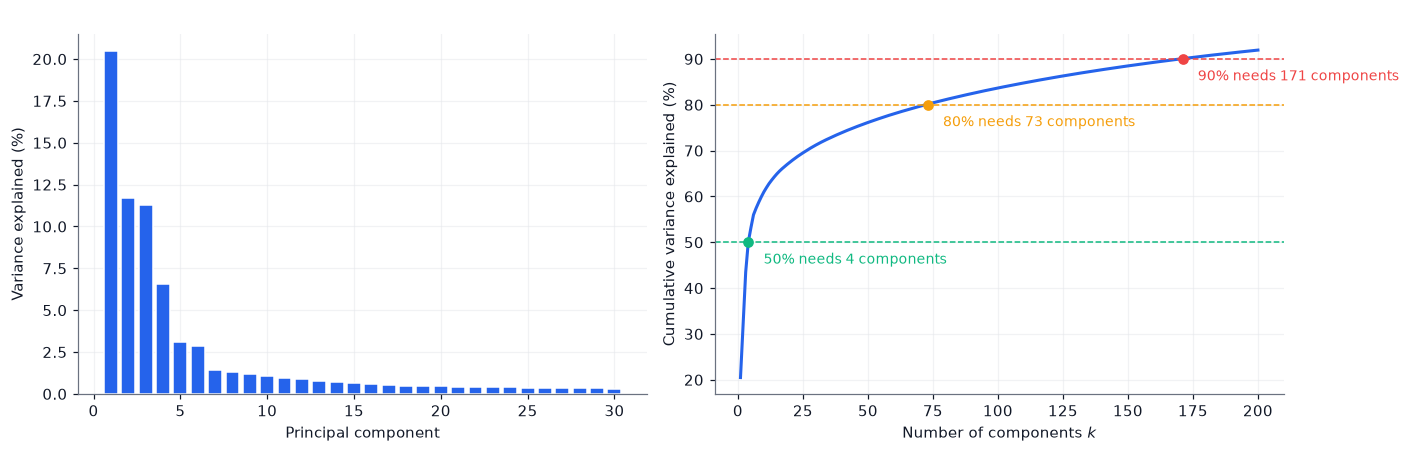

Variance explained by the first 2 / 10 / 50 components: [0.322, 0.61, 0.761] (out of 481 possible components for 481 samples)


In [6]:
U_tr, S_tr, Vt_tr = np.linalg.svd(Z["train"].astype(np.float64), full_matrices=False)
explained = S_tr**2 / np.sum(S_tr**2)
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(np.arange(1, 31), explained[:30] * 100, color=COLORS["blue"], edgecolor="white")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Variance explained (%)"); axes[0].set_title("Scree plot (first 30 components)")
axes[1].plot(np.arange(1, 201), cumulative[:200] * 100, color=COLORS["blue"])
for frac, color in [(0.5, COLORS["green"]), (0.8, COLORS["orange"]), (0.9, COLORS["red"])]:
    k_needed = int(np.searchsorted(cumulative, frac) + 1)
    axes[1].axhline(100 * frac, color=color, linestyle="--", linewidth=1); axes[1].scatter([k_needed], [100 * frac], color=color, zorder=5)
    axes[1].annotate(f"{int(100 * frac)}% needs {k_needed} components", (k_needed, 100 * frac), textcoords="offset points", xytext=(10, -14), fontsize=9, color=color)
axes[1].set_xlabel("Number of components $k$"); axes[1].set_ylabel("Cumulative variance explained (%)"); axes[1].set_title("The data are compressible")
finish(fig, "01_pca_spectrum")
print("Variance explained by the first 2 / 10 / 50 components:", [round(float(cumulative[k - 1]), 3) for k in (2, 10, 50)], "(out of", len(S_tr), "possible components for", len(tr), "samples)")

# Part I — The mathematics

## 5. The autoencoder framework

### 5.1 Definition and parameters

A (fully connected) autoencoder with encoder layers $d \to h_1 \to \dots \to k$ and a mirror-image decoder $k \to \dots \to h_1 \to d$ has

$$
\#\text{parameters} = \sum_{\text{layers}} (n_{in}+1)\,n_{out} .
$$

For example, $d = 2000$, one hidden layer of 256 units, and $k = 10$ gives $2000\cdot256 + 256 + 256\cdot10 + 10 + 10\cdot256 + 256 + 256\cdot2000 + 2000 \approx 1.04 \times 10^{6}$ parameters, to be learned from about 480 tumours: the model is **heavily over-parameterized**, which is why regularization (weight decay, noise, early stopping on validation reconstruction) matters.

### 5.2 Variants and what each one constrains

| Variant | Modification | What it prevents or encourages |
|---|---|---|
| **Undercomplete** | $k < d$ | the identity solution; forces compression |
| **Denoising** (Vincent *et al.*, 2008) | input is corrupted ($\tilde{x} = x + \varepsilon$ or random masking), target is the clean $x$ | copying the input; learns to remove noise (Section 8) |
| **Sparse** | penalty $\lambda\lVert z\rVert_1$ on the code | few active latent units per sample |
| **Contractive** | penalty on $\lVert \partial z / \partial x \rVert_F^2$ | a code that is insensitive to small input perturbations |
| **Variational** (Kingma and Welling, 2014) | the code is a *distribution*; a KL term pulls it towards a prior | a smooth, generative latent space (Section 9) |

### 5.3 Evaluating reconstruction

With standardized genes (each of unit variance on the training set), the mean squared error per gene is directly interpretable:

$$
\text{MSE} = \frac{1}{nd}\sum_{i,j}(x_{ij}-\hat{x}_{ij})^2, \qquad
R^2 = 1 - \frac{\text{MSE}}{\text{Var}} = 1 - \text{MSE}\quad(\text{when } \text{Var} = 1),
$$

the **fraction of variance explained**. The predictor "always output the training mean" ($\hat{x} = 0$ after standardization) has $\text{MSE} = 1$ ($R^2 = 0$).

## 6. A linear autoencoder is PCA

### 6.1 The Eckart–Young theorem

Let $X \in \mathbb{R}^{n \times d}$ be centred, with singular value decomposition $X = U\Sigma V^{\top}$ and singular values $\sigma_1 \ge \sigma_2 \ge \cdots$. Among all matrices $M$ of rank at most $k$, the truncated SVD $X_k = U_k\Sigma_kV_k^{\top}$ minimizes $\lVert X - M\rVert_F$, and

$$
\min_{\operatorname{rank}M \le k}\lVert X - M\rVert_F^{2} = \sum_{i > k}\sigma_i^{2} .
$$

*Proof sketch.* For any $M$ of rank $\le k$, Weyl's inequality for singular values gives $\sigma_{k+j}(X) \le \sigma_j(X - M) + \sigma_{k+1}(M) = \sigma_j(X-M)$ (because $\sigma_{k+1}(M) = 0$). Therefore $\lVert X-M\rVert_F^2 = \sum_j \sigma_j(X-M)^2 \ge \sum_j \sigma_{k+j}(X)^2 = \sum_{i>k}\sigma_i^2$, and $X_k$ attains this bound. $\square$

### 6.2 The linear autoencoder

Take an encoder $z = xW_e$ and a decoder $\hat{x} = zW_d$ without activation functions (centred data, no biases), with $W_e \in \mathbb{R}^{d \times k}$, $W_d \in \mathbb{R}^{k \times d}$. Then $\hat{X} = XW_eW_d$ has rank at most $k$, so by Eckart–Young

$$
\frac{1}{n}\lVert X - XW_eW_d\rVert_F^2 \;\ge\; \frac{1}{n}\sum_{i>k}\sigma_i^2,
$$

with equality when $W_eW_d = V_kV_k^{\top}$, the orthogonal projector onto the top-$k$ principal subspace. Baldi and Hornik (1989) showed more: the loss has **no spurious local minima** — every local minimum is a global minimum and spans the principal subspace. Two consequences:

1. **A linear autoencoder learns the same subspace as PCA** (a "PCA by gradient descent").
2. The individual **weights are not unique**: for any invertible $A \in \mathbb{R}^{k \times k}$, $(W_eA)(A^{-1}W_d) = W_eW_d$. The latent coordinates of an autoencoder equal the PCA scores only up to an *unknown invertible linear transformation* (and a nonlinear autoencoder is non-unique in even more ways). **Latent coordinates have no intrinsic meaning**; only the geometry they induce does.

The gradients, for the loss $L = \frac{1}{n}\lVert XW_eW_d - X\rVert_F^2$ with $E = XW_eW_d - X$:

$$
\frac{\partial L}{\partial W_d} = \frac{2}{n}(XW_e)^{\top}E, \qquad
\frac{\partial L}{\partial W_e} = \frac{2}{n}X^{\top}EW_d^{\top} .
$$

We check the theorem numerically in three steps: (a) truncated SVD against random low-rank approximations; (b) a linear autoencoder trained by gradient descent in NumPy against the PCA optimum, comparing the loss and the **principal angles** between the learned and the principal subspaces; (c) the non-uniqueness $A$.

In [7]:
# (a) Eckart-Young: truncated SVD against 300 random rank-k matrices, on the 100 highest-variance genes of the training set.
X100 = Z["train"][:, :100].astype(np.float64)
n_samples = len(X100)
k_demo = 3
U, S, Vt = np.linalg.svd(X100, full_matrices=False)
best_error = np.sum(S[k_demo:] ** 2)
X_k = (U[:, :k_demo] * S[:k_demo]) @ Vt[:k_demo]
print("Error of the truncated SVD, ||X - X_k||_F^2        :", round(float(np.sum((X100 - X_k) ** 2)), 4))
print("Eckart-Young formula, sum of the discarded sigma^2 :", round(float(best_error), 4))

rg = np.random.default_rng(0)
random_errors = []
for _ in range(300):
    Q, _ = np.linalg.qr(rg.normal(size=(X100.shape[1], k_demo)))                 # a random k-dimensional subspace
    random_errors.append(np.sum((X100 - X100 @ Q @ Q.T) ** 2))
print("Smallest error among 300 random k-dimensional subspaces:", round(float(min(random_errors)), 4), "(always larger than the SVD error)")
assert np.isclose(np.sum((X100 - X_k) ** 2), best_error) and min(random_errors) > best_error

Error of the truncated SVD, ||X - X_k||_F^2        : 15569.4047
Eckart-Young formula, sum of the discarded sigma^2 : 15569.4047
Smallest error among 300 random k-dimensional subspaces: 45029.2569 (always larger than the SVD error)


In [8]:
# (b) A linear autoencoder trained by full-batch gradient descent converges to the PCA subspace.
def linear_autoencoder_gd(X, k, iterations=30000, lr=None, seed=0, record_every=200):
    r = np.random.default_rng(seed)
    n, d = X.shape
    W_e, W_d = r.normal(0, 0.1, size=(d, k)), r.normal(0, 0.1, size=(k, d))
    lam_max = np.linalg.svd(X, compute_uv=False)[0] ** 2 / n
    lr = lr or 0.05 / lam_max
    history = []
    for it in range(iterations):
        Zc = X @ W_e
        E = Zc @ W_d - X
        if it % record_every == 0:
            history.append((it, float(np.sum(E ** 2) / n)))
        grad_d = (2 / n) * Zc.T @ E
        grad_e = (2 / n) * X.T @ E @ W_d.T
        W_d -= lr * grad_d; W_e -= lr * grad_e
    return W_e, W_d, np.array(history)

t0 = time.time()
W_e, W_d, hist = linear_autoencoder_gd(X100, k_demo)
optimum = best_error / n_samples
final_loss = float(np.sum((X100 @ W_e @ W_d - X100) ** 2) / n_samples)
print(f"Done in {time.time() - t0:.1f} s")
print(f"Linear autoencoder loss after training: {final_loss:.4f} | PCA optimum: {optimum:.4f} | relative gap: {(final_loss - optimum) / optimum:.2e}")

# Principal angles between the row space of W_d (what the decoder can produce) and the top-k principal subspace.
Q_ae, _ = np.linalg.qr(W_d.T)                                                    # (d, k), orthonormal basis of the decoder subspace
cosines = np.linalg.svd(Q_ae.T @ Vt[:k_demo].T, compute_uv=False)
angles = np.degrees(np.arccos(np.clip(cosines, -1, 1)))
print("Principal angles between the autoencoder subspace and the PCA subspace (degrees):", np.round(angles, 3))
assert (final_loss - optimum) / optimum < 0.01 and angles.max() < 5

# (c) Non-uniqueness: an invertible A leaves the reconstruction unchanged but changes the latent coordinates.
A = np.random.default_rng(1).normal(size=(k_demo, k_demo)) + 3 * np.eye(k_demo)
rec_same = np.allclose(X100 @ (W_e @ A) @ (np.linalg.inv(A) @ W_d), X100 @ W_e @ W_d)
print("Reconstruction unchanged by (W_e A, A^-1 W_d):", rec_same, "| the latent codes change:", not np.allclose(X100 @ W_e, X100 @ (W_e @ A)))

Done in 16.1 s
Linear autoencoder loss after training: 32.3696 | PCA optimum: 32.3688 | relative gap: 2.41e-05
Principal angles between the autoencoder subspace and the PCA subspace (degrees): [0.002 0.004 0.006]
Reconstruction unchanged by (W_e A, A^-1 W_d): True | the latent codes change: True


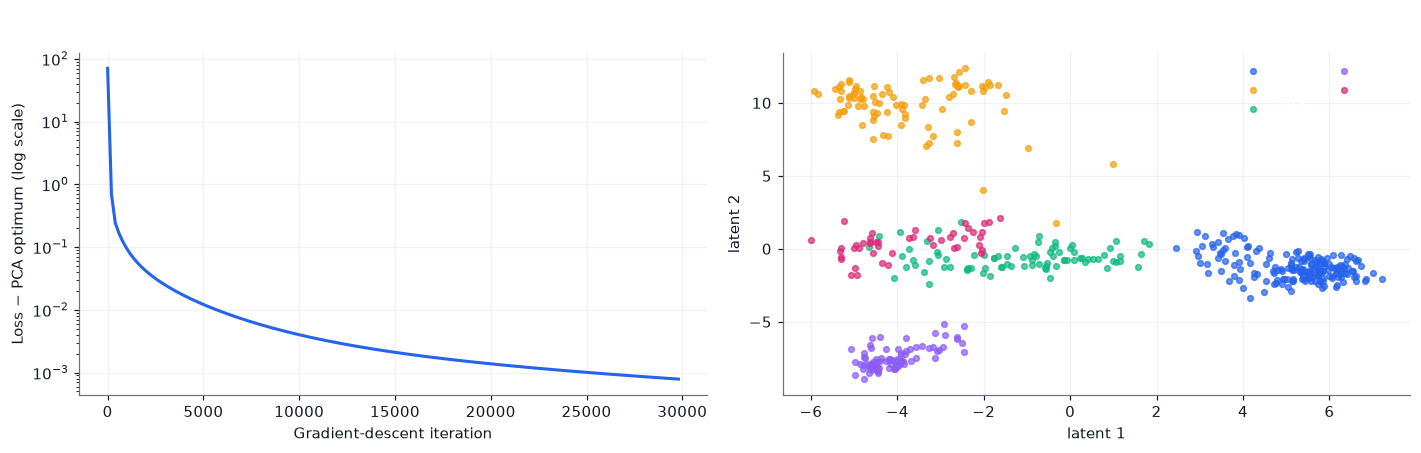

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].semilogy(hist[:, 0], hist[:, 1] - optimum + 1e-9, color=COLORS["blue"])
axes[0].set_xlabel("Gradient-descent iteration"); axes[0].set_ylabel("Loss \u2212 PCA optimum (log scale)")
axes[0].set_title("A linear autoencoder converges to the PCA solution")

# Compare the 2D codes of the linear autoencoder and of PCA for k = 2 (they agree up to an invertible linear map).
W_e2, W_d2, _ = linear_autoencoder_gd(X100, 2)
codes_ae, codes_pca = X100 @ W_e2, X100 @ Vt[:2].T
M, *_ = np.linalg.lstsq(codes_pca, codes_ae, rcond=None)                          # best linear map from PCA scores to AE codes
residual = np.linalg.norm(codes_ae - codes_pca @ M) / np.linalg.norm(codes_ae)
for k_, c in enumerate(GENE_CLASSES):
    sel = y["train"] == k_
    axes[1].scatter(codes_ae[sel, 0], codes_ae[sel, 1], s=14, alpha=0.7, color=CLASS_COLORS[c], label=c)
axes[1].set_xlabel("latent 1"); axes[1].set_ylabel("latent 2"); axes[1].legend(ncol=2, fontsize=8)
axes[1].set_title(f"Linear AE codes (k = 2): a linear transformation of the PCA scores\n(relative residual of the best linear fit: {residual:.1e})", fontsize=10.5)
finish(fig, "02_linear_ae_equals_pca")

The gradient descent reaches the PCA optimum within a tiny relative gap and the principal angles are close to zero: **the linear autoencoder is PCA**. The code of the linear autoencoder (right) is a linear transformation of the PCA scores, as the theory predicts.

*So why use a nonlinear autoencoder at all?* If the data lie near a **curved** manifold, a linear subspace needs more dimensions than a nonlinear map would. The experiments in Part II test whether this happens for gene expression.

## 7. The reconstruction loss as a likelihood, and the effect of scaling

Minimizing the mean squared error is **maximum likelihood** under the assumption that each gene is the decoder output plus independent Gaussian noise:

$$
x_j \mid z \sim \mathcal{N}\big(g_\theta(z)_j,\ \sigma^2\big) \quad\Longrightarrow\quad
-\log p(x\mid z) = \frac{1}{2\sigma^2}\lVert x - g_\theta(z)\rVert^2 + \text{const}.
$$

Other data types call for other likelihoods: **count data** (raw RNA-seq or single-cell counts) are better modelled by the Poisson or negative-binomial distribution (the basis of methods such as scVI and DCA); binary data by the Bernoulli distribution (binary cross-entropy). Our values are continuous and roughly log-scaled, for which the Gaussian is a reasonable first choice.

**Scaling decides what the model pays attention to.** The squared error adds up the contributions of all genes: a gene with a large variance contributes more than one with a small variance. Without standardization, the highest-variance genes dominate the loss and the autoencoder would mostly reconstruct them. The check below measures this on our (unstandardized) selected genes; after standardization every gene has the same weight.

In [10]:
raw_selected = X_raw[tr][:, prep["cols"]].astype(np.float64)
var_raw = raw_selected.var(axis=0)
share = np.sort(var_raw)[::-1].cumsum() / var_raw.sum()
n1, n10 = int(0.01 * D), int(0.10 * D)
print(f"Without standardization, the top 1% of the genes ({n1}) carry {100 * share[n1 - 1]:.1f}% of the total variance (the loss),")
print(f"and the top 10% ({n10}) carry {100 * share[n10 - 1]:.1f}%. After standardization every gene carries {100 / D:.3f}%.")
print("Check: for standardized training data, the MSE of the 'always the mean' predictor is", round(float(np.mean(Z['train'] ** 2)), 3), "(R^2 = 0)")

Without standardization, the top 1% of the genes (20) carry 3.5% of the total variance (the loss),
and the top 10% (200) carry 22.1%. After standardization every gene carries 0.050%.
Check: for standardized training data, the MSE of the 'always the mean' predictor is 1.0 (R^2 = 0)


## 8. The denoising autoencoder and Tweedie's formula

A **denoising autoencoder (DAE)** corrupts its input, $\tilde{x} = x + \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, \sigma^2 I)$ (or sets random entries to zero), and is trained to reconstruct the **clean** $x$:

$$
\min_{\phi,\theta}\ \mathbb{E}_{x}\,\mathbb{E}_{\varepsilon}\ \big\lVert x - g_\theta\big(f_\phi(x+\varepsilon)\big)\big\rVert^2 .
$$

For squared loss, the best possible reconstruction function $r(\tilde{x})$ is the **conditional mean** (Notebook 05: the minimizer of the squared error is $\mathbb{E}[x \mid \tilde{x}]$):

$$
r^{*}(\tilde{x}) = \mathbb{E}[x \mid \tilde{x}] = \tilde{x} + \sigma^{2}\,\nabla_{\tilde{x}}\log p_\sigma(\tilde{x}),
$$

where $p_\sigma$ is the density of the *noisy* data. This is **Tweedie's formula** (Efron, 2011). Its meaning: the optimal denoiser moves each noisy point **uphill along the log-density** (the *score* $\nabla\log p_\sigma$), by an amount proportional to $\sigma^2$. A denoising autoencoder therefore learns, implicitly, the *shape of the data distribution* (Vincent, 2011; Alain and Bengio, 2014); it cannot simply copy its input, because the input contains noise that the target does not. In practice a DAE is a strong regularizer for representation learning.

*Verification in one dimension.* Let the data follow a mixture of two Gaussians, $p(x) = \sum_m \pi_m\mathcal{N}(\mu_m, s^2)$. Then $p_\sigma(\tilde{x}) = \sum_m \pi_m\mathcal{N}(\tilde{x}; \mu_m, s^2+\sigma^2)$ and the posterior mean is known in closed form. We compare (i) the posterior mean, (ii) Tweedie's expression with the score computed by **finite differences** of $\log p_\sigma$, and (iii) a **Monte Carlo estimate** of $\mathbb{E}[x\mid\tilde{x}]$ obtained by simulating noisy data and averaging $x$ in narrow bins of $\tilde{x}$.

Max |posterior mean - Tweedie expression| on the grid: 9.316381333057677e-09
Max |Monte Carlo conditional mean - posterior mean| over the bins: 0.0239


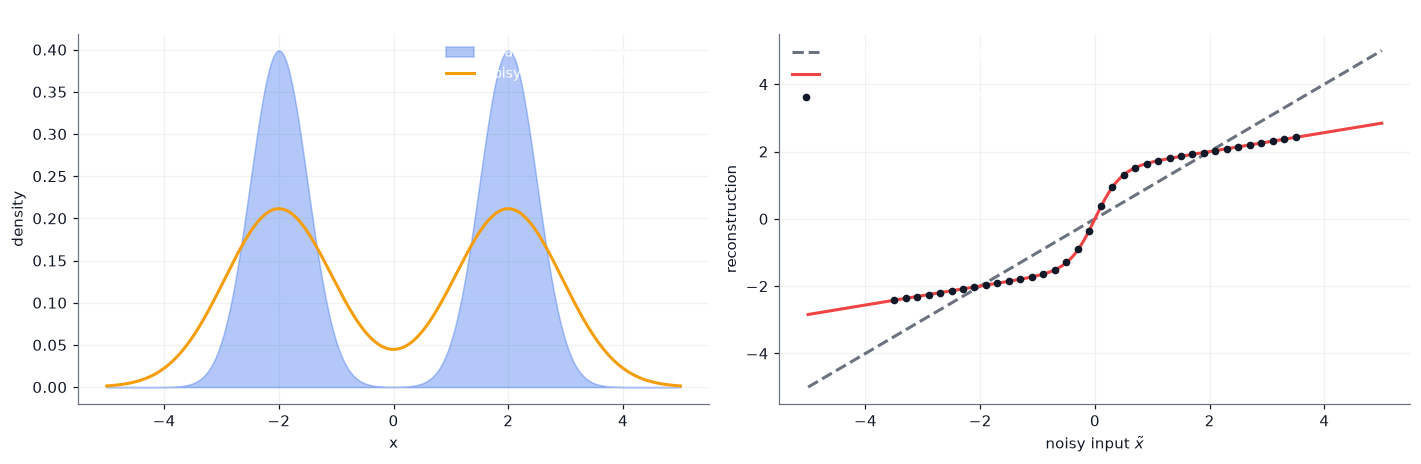

In [11]:
pi_m, mu_m, s_data, sigma_noise = np.array([0.5, 0.5]), np.array([-2.0, 2.0]), 0.5, 0.8
gauss = lambda x, mu, var: np.exp(-0.5 * (x - mu) ** 2 / var) / np.sqrt(2 * np.pi * var)

def noisy_density(x_tilde):
    return sum(w * gauss(x_tilde, m, s_data**2 + sigma_noise**2) for w, m in zip(pi_m, mu_m))

def posterior_mean(x_tilde):
    comp = np.stack([w * gauss(x_tilde, m, s_data**2 + sigma_noise**2) for w, m in zip(pi_m, mu_m)])
    weights = comp / comp.sum(axis=0)
    return sum(wt * (m + s_data**2 / (s_data**2 + sigma_noise**2) * (x_tilde - m)) for wt, m in zip(weights, mu_m))

grid = np.linspace(-5, 5, 2001); h = 1e-4
score = (np.log(noisy_density(grid + h)) - np.log(noisy_density(grid - h))) / (2 * h)         # numerical score of the noisy density
tweedie = grid + sigma_noise**2 * score
print("Max |posterior mean - Tweedie expression| on the grid:", float(np.abs(posterior_mean(grid) - tweedie).max()))
assert np.abs(posterior_mean(grid) - tweedie).max() < 1e-5

# Monte Carlo: simulate (x, x_tilde) pairs and average x in narrow bins of x_tilde.
rs = np.random.default_rng(0)
comp_idx = rs.choice(2, size=3_000_000, p=pi_m)
x_samples = mu_m[comp_idx] + s_data * rs.normal(size=3_000_000)
x_tilde_samples = x_samples + sigma_noise * rs.normal(size=3_000_000)
bin_centres = np.linspace(-3.5, 3.5, 36)
mc_mean = np.array([x_samples[np.abs(x_tilde_samples - c) < 0.05].mean() for c in bin_centres])
print("Max |Monte Carlo conditional mean - posterior mean| over the bins:", round(float(np.abs(mc_mean - posterior_mean(bin_centres)).max()), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].fill_between(grid, sum(w * gauss(grid, m, s_data**2) for w, m in zip(pi_m, mu_m)), color=COLORS["blue"], alpha=0.35, label="clean data density $p(x)$")
axes[0].plot(grid, noisy_density(grid), color=COLORS["orange"], label=f"noisy data density $p_\\sigma$ (\u03c3 = {sigma_noise})")
axes[0].set_xlabel("x"); axes[0].set_ylabel("density"); axes[0].set_title("Two clusters, blurred by noise"); axes[0].legend()
axes[1].plot(grid, grid, color=COLORS["gray"], linestyle="--", label="identity (no denoising)")
axes[1].plot(grid, posterior_mean(grid), color=COLORS["red"], label="optimal denoiser $E[x \\mid \\tilde{x}]$")
axes[1].scatter(bin_centres, mc_mean, color=COLORS["dark"], s=16, zorder=5, label="Monte Carlo estimate")
axes[1].set_xlabel(r"noisy input $\tilde{x}$"); axes[1].set_ylabel("reconstruction"); axes[1].set_title("The optimal denoiser pulls points towards the clusters"); axes[1].legend(loc="upper left")
finish(fig, "03_tweedie_denoiser")

## 9. Towards a generative model: the variational autoencoder (VAE)

A plain autoencoder maps each sample to a *point* $z$; the latent space between the points may be meaningless, so decoding a random $z$ need not give a realistic sample. The **variational autoencoder** makes the model probabilistic:

$$
p(z) = \mathcal{N}(0, I), \qquad p_\theta(x \mid z)\ \text{(decoder)}, \qquad q_\phi(z \mid x) = \mathcal{N}\big(\mu_\phi(x), \operatorname{diag}\sigma_\phi^2(x)\big)\ \text{(encoder)} .
$$

### 9.1 The evidence lower bound (ELBO)

The log-likelihood of one sample is $\log p(x) = \log \int p(x\mid z)p(z)\,dz$, which is intractable. For any $q(z \mid x)$,

$$
\log p(x) = \underbrace{\mathbb{E}_{q}\big[\log p_\theta(x \mid z)\big] - D_{\mathrm{KL}}\big(q_\phi(z \mid x)\,\Vert\,p(z)\big)}_{\text{ELBO}} \;+\; D_{\mathrm{KL}}\big(q_\phi(z \mid x)\,\Vert\,p_\theta(z \mid x)\big) \;\ge\; \text{ELBO},
$$

because a KL divergence is non-negative. The ELBO is tight exactly when $q$ equals the true posterior. Training maximizes the ELBO: the first term is the (negative) **reconstruction loss**, the second a **regularizer** that keeps the codes close to the prior (a smooth, usable latent space). A weight $\beta$ on the KL term gives the $\beta$-VAE (Higgins *et al.*, 2017).

### 9.2 Two ingredients

1. **Closed-form KL** between a diagonal Gaussian and the prior:
$$
D_{\mathrm{KL}}\big(\mathcal{N}(\mu, \sigma^2 I)\,\Vert\,\mathcal{N}(0, I)\big) = \frac{1}{2}\sum_{j=1}^{k}\big(\mu_j^2 + \sigma_j^2 - 1 - \ln \sigma_j^2\big).
$$
2. **Reparameterization trick:** to differentiate through the sampling, write $z = \mu + \sigma\odot\varepsilon$ with $\varepsilon \sim \mathcal{N}(0, I)$. The randomness is now in $\varepsilon$, which does not depend on the parameters, so gradients flow through $\mu$ and $\sigma$.

We verify all three claims numerically (the KL formula, the ELBO identity in a model with a known posterior, and the reparameterized gradient).

In [12]:
rg = np.random.default_rng(0)
# (1) Closed-form KL against a Monte Carlo estimate of E_q[log q - log p], for a 3-dimensional diagonal Gaussian.
mu_q, sigma_q = np.array([0.7, -1.1, 0.2]), np.array([0.5, 1.4, 0.9])
kl_formula = 0.5 * np.sum(mu_q**2 + sigma_q**2 - 1 - np.log(sigma_q**2))
eps = rg.normal(size=(2_000_000, 3)); z = mu_q + sigma_q * eps
log_q = np.sum(-0.5 * ((z - mu_q) / sigma_q) ** 2 - np.log(sigma_q) - 0.5 * np.log(2 * np.pi), axis=1)
log_p = np.sum(-0.5 * z**2 - 0.5 * np.log(2 * np.pi), axis=1)
print(f"KL divergence: closed form {kl_formula:.4f} | Monte Carlo {np.mean(log_q - log_p):.4f}")
assert abs(kl_formula - np.mean(log_q - log_p)) < 0.01

# (2) The ELBO identity in a conjugate model: z ~ N(0, 1), x | z ~ N(z, s^2). Then log p(x) and the posterior are known exactly.
s2, x_obs = 0.6, 1.3
log_px = -0.5 * np.log(2 * np.pi * (1 + s2)) - x_obs**2 / (2 * (1 + s2))                    # x ~ N(0, 1 + s^2)
post_mean, post_var = x_obs / (1 + s2), s2 / (1 + s2)

def elbo(m, v):
    expected_loglik = -0.5 * np.log(2 * np.pi * s2) - ((x_obs - m) ** 2 + v) / (2 * s2)
    kl_prior = 0.5 * (m**2 + v - 1 - np.log(v))
    return expected_loglik - kl_prior

def kl_gauss(m1, v1, m2, v2):
    return 0.5 * (np.log(v2 / v1) + (v1 + (m1 - m2) ** 2) / v2 - 1)

print(f"\nlog p(x) = {log_px:.5f}")
print(f"ELBO with the exact posterior q* : {elbo(post_mean, post_var):.5f}   (tight: equals log p(x))")
for m, v in [(0.0, 1.0), (0.5, 0.3), (1.0, 0.5), (1.5, 0.1)]:
    gap = log_px - elbo(m, v)
    print(f"ELBO with q = N({m}, {v}): {elbo(m, v):.5f} | gap to log p(x) = {gap:.5f} | KL(q || posterior) = {kl_gauss(m, v, post_mean, post_var):.5f}")
    assert np.isclose(gap, kl_gauss(m, v, post_mean, post_var))

# (3) Reparameterization: d/d(mu) E_q[z^2] = 2 mu, estimated by the average of the pathwise derivative 2z.
mu0, sig0 = 0.8, 1.3
z_rep = mu0 + sig0 * rg.normal(size=2_000_000)
print(f"\nReparameterized gradient of E[z^2] with respect to mu: Monte Carlo {np.mean(2 * z_rep):.4f} | exact {2 * mu0:.4f}")

KL divergence: closed form 1.3420 | Monte Carlo 1.3422

log p(x) = -1.68207
ELBO with the exact posterior q* : -1.68207   (tight: equals log p(x))
ELBO with q = N(0.0, 1.0): -2.90519 | gap to log p(x) = 1.22313 | KL(q || posterior) = 1.22313
ELBO with q = N(0.5, 0.3): -1.82385 | gap to log p(x) = 0.14178 | KL(q || posterior) = 0.14178
ELBO with q = N(1.0, 0.5): -1.75177 | gap to log p(x) = 0.06970 | KL(q || posterior) = 0.06970
ELBO with q = N(1.5, 0.1): -2.60648 | gap to log p(x) = 0.92442 | KL(q || posterior) = 0.92442

Reparameterized gradient of E[z^2] with respect to mu: Monte Carlo 1.5972 | exact 1.6000


The gap between $\log p(x)$ and the ELBO equals $D_{\mathrm{KL}}(q\,\Vert\,p(z\mid x))$ exactly, as the identity states.

We do **not** train a VAE in this notebook (it needs a custom loss with a sampling layer, and its latent space is *regularized* rather than *compressive* in the sense of Part II), but a compact implementation in Keras 3 is given in the exercises (B.8) with the loss weights derived here. For gene-expression data, VAEs have been used to learn latent spaces of cancer transcriptomes (Way and Greene, 2018).

# Part II — Experiments

## 10. Tools for the experiments

Everything below that does not need a neural network is written in NumPy, so that each method can be inspected:

- **PCA**: from the singular value decomposition of the training matrix (computed in Section 4.1);
- **nearest-neighbour classifier** (5 neighbours, majority vote, ties broken by distance) and a **ridge classifier** (as in Notebooks 06–07), used to judge how much *class information* a representation keeps — the labels are used **only here**, never to train an autoencoder;
- **k-means** (with k-means++ initialization, 10 restarts) and the **adjusted Rand index (ARI)** to judge unsupervised clustering:

$$
\text{ARI} = \frac{\sum_{ij}\binom{n_{ij}}{2} - \Big[\sum_i\binom{a_i}{2}\sum_j\binom{b_j}{2}\Big]\Big/\binom{n}{2}}{\tfrac{1}{2}\Big[\sum_i\binom{a_i}{2}+\sum_j\binom{b_j}{2}\Big] - \Big[\sum_i\binom{a_i}{2}\sum_j\binom{b_j}{2}\Big]\Big/\binom{n}{2}},
$$

where $n_{ij}$ counts the samples in cluster $i$ and class $j$, and $a_i$, $b_j$ are the row and column sums. ARI is 1 for identical partitions and about 0 for random ones (it corrects for chance).

The codes of every method are **standardized** (mean and standard deviation of the training codes) before being used, so that no representation is favoured by an arbitrary scale.

In [13]:
def confusion_matrix_np(y_true, y_pred, n_classes=5):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def macro_f1_and_accuracy(y_true, y_pred, n_classes=5):
    cm = confusion_matrix_np(y_true, y_pred, n_classes).astype(float)
    tp, predicted, support = np.diag(cm), cm.sum(axis=0), cm.sum(axis=1)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    return float(np.trace(cm) / cm.sum()), float(f1[support > 0].mean())

def standardize_codes(train_codes, *others):
    mu, sd = train_codes.mean(axis=0), train_codes.std(axis=0) + 1e-8
    return [(c - mu) / sd for c in (train_codes, *others)]

def knn_predict(Xtr, ytr, Xq, k=5, n_classes=5):
    d2 = (Xq**2).sum(1)[:, None] + (Xtr**2).sum(1)[None, :] - 2 * Xq @ Xtr.T
    idx = np.argsort(d2, axis=1)[:, :k]
    votes, weights = ytr[idx], 1 + 0.01 * (k - np.arange(k))                         # ties are broken in favour of nearer neighbours
    scores = np.stack([((votes == c) * weights).sum(axis=1) for c in range(n_classes)], axis=1)
    return scores.argmax(axis=1)

def ridge_predict(Xtr, ytr, Xq, lam, n_classes=5):
    Y = np.eye(n_classes)[ytr]; y_bar = Y.mean(axis=0)
    Xtr, Xq = Xtr.astype(np.float64), Xq.astype(np.float64)
    if Xtr.shape[1] > len(Xtr):                                                      # dual form when there are more features than samples
        alpha = np.linalg.solve(Xtr @ Xtr.T + lam * np.eye(len(Xtr)), Y - y_bar)
        return ((Xq @ Xtr.T) @ alpha + y_bar).argmax(axis=1)
    W = np.linalg.solve(Xtr.T @ Xtr + lam * np.eye(Xtr.shape[1]), Xtr.T @ (Y - y_bar))
    return (Xq @ W + y_bar).argmax(axis=1)

def kmeans_numpy(X, n_clusters, n_init=10, iters=100, seed=0):
    r = np.random.default_rng(seed); best = None
    for _ in range(n_init):
        centers = [X[r.integers(len(X))]]
        for _ in range(n_clusters - 1):                                              # k-means++ initialization
            d2 = np.min([((X - c) ** 2).sum(1) for c in centers], axis=0)
            centers.append(X[r.choice(len(X), p=d2 / d2.sum())])
        centers = np.array(centers)
        for _ in range(iters):
            labels = ((X[:, None, :] - centers[None]) ** 2).sum(2).argmin(1)
            new = np.array([X[labels == j].mean(0) if np.any(labels == j) else centers[j] for j in range(n_clusters)])
            if np.allclose(new, centers):
                break
            centers = new
        inertia = ((X - centers[labels]) ** 2).sum()
        if best is None or inertia < best[0]:
            best = (inertia, centers)
    return best[1]

def assign_clusters(X, centers):
    return ((X[:, None, :] - centers[None]) ** 2).sum(2).argmin(1)

def adjusted_rand_index(a, b):
    a, b = np.asarray(a), np.asarray(b)
    _, ai = np.unique(a, return_inverse=True); _, bi = np.unique(b, return_inverse=True)
    table = np.zeros((ai.max() + 1, bi.max() + 1)); np.add.at(table, (ai, bi), 1)
    comb2 = lambda x: x * (x - 1) / 2
    sum_ij, sum_a, sum_b, n = comb2(table).sum(), comb2(table.sum(1)).sum(), comb2(table.sum(0)).sum(), comb2(len(a))
    expected = sum_a * sum_b / n
    return float((sum_ij - expected) / (0.5 * (sum_a + sum_b) - expected))

def auc_rank(y_true, score):
    """AUC = P(score of a positive > score of a negative) by average ranks (Notebook 07)."""
    y_true = np.asarray(y_true).astype(bool); n_pos, n_neg = y_true.sum(), (~y_true).sum()
    order = np.argsort(score, kind="stable"); ranks = np.empty(len(score)); s = np.asarray(score)[order]
    i = 0
    while i < len(score):
        j = i
        while j + 1 < len(score) and s[j + 1] == s[i]:
            j += 1
        ranks[order[i:j + 1]] = (i + j) / 2 + 1; i = j + 1
    return float((ranks[y_true].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))

# Quick checks of the tools: ARI of identical partitions (with relabelled clusters) is 1; of independent random labels about 0.
a_lab = np.random.default_rng(0).integers(0, 4, 400)
print("ARI(identical partitions, permuted names) =", round(adjusted_rand_index(a_lab, (a_lab + 1) % 4), 3),
      "| ARI(independent random labels) =", round(adjusted_rand_index(a_lab, np.random.default_rng(1).integers(0, 4, 400)), 3))
print("AUC of a perfect score:", auc_rank([0, 0, 1, 1], [0.1, 0.2, 0.8, 0.9]), "| of a constant score:", auc_rank([0, 1, 0, 1], [0.5] * 4))

ARI(identical partitions, permuted names) = 1.0 | ARI(independent random labels) = -0.001
AUC of a perfect score: 1.0 | of a constant score: 0.5


## 11. The models

**PCA** (Section 6) with $k$ components, from the SVD of the training data.

**Autoencoder (AE).** Encoder $2000 \to 256\ (\text{ReLU}) \to k$, decoder $k \to 256\ (\text{ReLU}) \to 2000$, with a small L2 weight penalty ($10^{-4}$). The encoder and the decoder are separate `Sequential` models, so that the code can be extracted after training.

**Denoising autoencoder (DAE).** The same network, with a `GaussianNoise(0.5)` layer in front of the encoder (active only during training): the input is corrupted with noise of standard deviation 0.5 (in units of the standard deviation of each gene), while the target remains the clean profile (Section 8).

**Training.** Adam ($10^{-3}$), batch size 32, mean squared error, early stopping on the **validation reconstruction error** (patience 20, best weights restored). Every configuration is trained with several seeds.

In [14]:
DAE_NOISE = 0.5

def build_autoencoder(k, hidden=(256,), noise_std=0.0, l2=1e-4, name="autoencoder", input_dim=None):
    d_in = input_dim or D
    reg = keras.regularizers.L2(l2)
    enc = [keras.layers.Input(shape=(d_in,), name="expression")]
    for i, h in enumerate(hidden, start=1):
        enc.append(keras.layers.Dense(h, activation="relu", kernel_regularizer=reg, name=f"enc_{i}"))
    enc.append(keras.layers.Dense(k, name="latent"))
    encoder = keras.Sequential(enc, name=f"{name}_encoder")
    dec = [keras.layers.Input(shape=(k,), name="code")]
    for i, h in enumerate(reversed(hidden), start=1):
        dec.append(keras.layers.Dense(h, activation="relu", kernel_regularizer=reg, name=f"dec_{i}"))
    dec.append(keras.layers.Dense(d_in, name="reconstruction"))
    decoder = keras.Sequential(dec, name=f"{name}_decoder")
    layers = [keras.layers.Input(shape=(d_in,), name="input")]
    if noise_std > 0:
        layers.append(keras.layers.GaussianNoise(noise_std, name="corruption"))
    layers += [encoder, decoder]
    return keras.Sequential(layers, name=name), encoder, decoder

def train_autoencoder(k, seed, X_train, X_val, noise_std=0.0, epochs=300, patience=20, name="autoencoder"):
    keras.utils.set_random_seed(seed)
    ae, enc, dec = build_autoencoder(k, noise_std=noise_std, name=name, input_dim=X_train.shape[1])
    ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    history = ae.fit(X_train, X_train, validation_data=(X_val, X_val), epochs=epochs, batch_size=32,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)], verbose=0)
    return ae, enc, dec, history.history

mse = lambda a, b: float(np.mean((np.asarray(a, dtype=np.float64) - np.asarray(b, dtype=np.float64)) ** 2))

preview, _, _ = build_autoencoder(K_MAIN)
print(f"Autoencoder with k = {K_MAIN}: {preview.count_params():,} parameters for {len(tr)} training tumours")
print("PCA with the same k has", D * K_MAIN, "free parameters (the projection matrix)")

Autoencoder with k = 10: 1,031,642 parameters for 481 training tumours
PCA with the same k has 20000 free parameters (the projection matrix)


## 12. Experiment E1 — reconstruction error against the bottleneck size

For each $k$ in the grid we measure the **validation** mean squared error of PCA, of the AE (mean ± SD over seeds), and of the DAE. Because the genes are standardized, $\text{MSE} = 1 - R^2$.

The bottleneck size $k$ for the downstream analyses, $K_{\text{main}} = 10$, was fixed **before** looking at any results (so it is not tuned on the results below).

In [15]:
store = {}                                    # (method, k, seed) -> (autoencoder, encoder, decoder)
val_mse = {"PCA": {}, "Autoencoder": {}, "Denoising autoencoder": {}}
epochs_run = {}
t0 = time.time()
for k in K_GRID:
    Vk = Vt_tr[:k]
    val_mse["PCA"][k] = [mse(Z["val"], (Z["val"] @ Vk.T) @ Vk)]
    for method, noise in [("Autoencoder", 0.0), ("Denoising autoencoder", DAE_NOISE)]:
        errs = []
        for s in range(N_SEEDS):
            ae, enc, dec, hist = train_autoencoder(k, SEED + s, Z["train"], Z["val"], noise_std=noise, name=f"{method.split()[0].lower()}_k{k}_s{s}")
            store[(method, k, s)] = (ae, enc, dec)
            errs.append(mse(Z["val"], ae.predict(Z["val"], verbose=0))); epochs_run[(method, k, s)] = len(hist["loss"])
        val_mse[method][k] = errs
    print(f"k = {k:3d}: PCA {val_mse['PCA'][k][0]:.3f} | AE {np.mean(val_mse['Autoencoder'][k]):.3f} | DAE {np.mean(val_mse['Denoising autoencoder'][k]):.3f}   (elapsed {time.time() - t0:.0f} s)")

k =   2: PCA 0.689 | AE 0.479 | DAE 0.471   (elapsed 250 s)
k =   5: PCA 0.487 | AE 0.416 | DAE 0.416   (elapsed 439 s)
k =  10: PCA 0.415 | AE 0.391 | DAE 0.388   (elapsed 612 s)
k =  20: PCA 0.364 | AE 0.373 | DAE 0.369   (elapsed 740 s)
k =  50: PCA 0.311 | AE 0.369 | DAE 0.363   (elapsed 849 s)


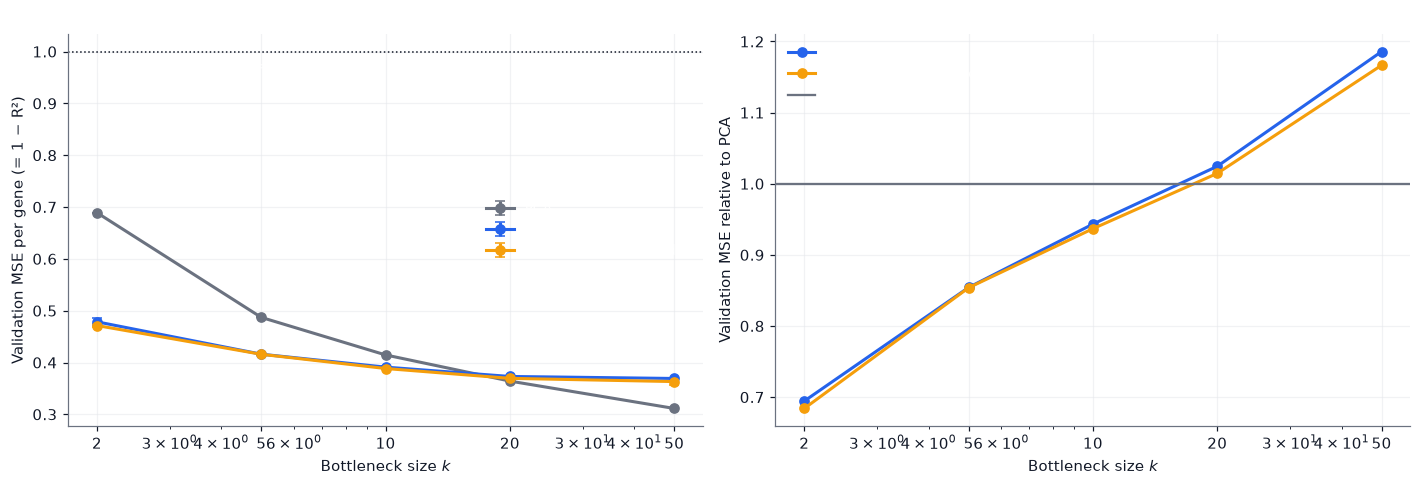

,PCA,Autoencoder,Denoising autoencoder
k = 2,0.689,0.479 ± 0.008,0.471 ± 0.002
k = 5,0.487,0.416 ± 0.002,0.416 ± 0.001
k = 10,0.415,0.391 ± 0.002,0.388 ± 0.001
k = 20,0.364,0.373 ± 0.001,0.369 ± 0.003
k = 50,0.311,0.369 ± 0.002,0.363 ± 0.008


R² at k = 10: PCA 0.585 | AE 0.609 | DAE 0.612


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method in val_mse:
    means = np.array([np.mean(val_mse[method][k]) for k in K_GRID]); sds = np.array([np.std(val_mse[method][k]) for k in K_GRID])
    axes[0].errorbar(K_GRID, means, yerr=sds, marker="o", capsize=3, color=METHOD_COLORS[method], label=method)
axes[0].axhline(1.0, color=COLORS["dark"], linestyle=":", linewidth=1); axes[0].annotate("predicting the mean (R\u00b2 = 0)", (K_GRID[0], 0.985), fontsize=8.5, va="top")
axes[0].set_xscale("log"); axes[0].set_xticks(K_GRID); axes[0].set_xticklabels(K_GRID)
axes[0].set_xlabel("Bottleneck size $k$"); axes[0].set_ylabel("Validation MSE per gene (= 1 \u2212 R\u00b2)"); axes[0].set_title("Reconstruction error against the bottleneck size"); axes[0].legend()

# Relative to PCA: the ratio shows where the nonlinearity (or the regularization) helps.
for method in ["Autoencoder", "Denoising autoencoder"]:
    ratio = [np.mean(val_mse[method][k]) / val_mse["PCA"][k][0] for k in K_GRID]
    axes[1].plot(K_GRID, ratio, marker="o", color=METHOD_COLORS[method], label=method)
axes[1].axhline(1.0, color=METHOD_COLORS["PCA"], linewidth=1.5, label="PCA"); axes[1].set_xscale("log"); axes[1].set_xticks(K_GRID); axes[1].set_xticklabels(K_GRID)
axes[1].set_xlabel("Bottleneck size $k$"); axes[1].set_ylabel("Validation MSE relative to PCA"); axes[1].set_title("Below 1: better than PCA; above 1: worse"); axes[1].legend()
finish(fig, "04_reconstruction_vs_k")

table = pd.DataFrame({method: {f"k = {k}": f"{np.mean(v[k]):.3f}" + (f" \u00b1 {np.std(v[k]):.3f}" if len(v[k]) > 1 else "") for k in K_GRID} for method, v in val_mse.items()})
display(table)
print("R\u00b2 at k = %d: PCA %.3f | AE %.3f | DAE %.3f" % (K_MAIN, 1 - val_mse["PCA"][K_MAIN][0], 1 - np.mean(val_mse["Autoencoder"][K_MAIN]), 1 - np.mean(val_mse["Denoising autoencoder"][K_MAIN])))

How to read these results (compare with your own numbers):

- Every method explains a large fraction of the variance with a few dozen numbers — the data are compressible (Section 4.1).
- With **only 480 training tumours**, a nonlinear autoencoder with about a million weights has **no guarantee** of beating PCA: it needs regularization to avoid memorizing the training set, and PCA is the *optimal linear* solution. Differences between PCA and the autoencoders are usually modest, and the ratio plot shows whether the nonlinearity helps (ratio below 1) or hurts (above 1) at each $k$.
- The **DAE** typically has a *higher* clean-data reconstruction error than the plain AE (it was trained to ignore part of the input) but its codes are often *more robust*; Section 14 tests this directly.
- Because only 480 samples are available for training, the reconstruction error on **new** tumours (validation) is higher than on the training tumours: the gap is the price of fitting the training set (Notebook 06).

## 13. Experiment E2 — is the latent space organized by cancer type?

The labels were never used for training. We now ask, **after the fact**, whether the codes keep the class structure.

### 13.1 Two-dimensional maps

With $k = 2$ we can look at the codes directly: PCA, the autoencoder, and the denoising autoencoder (first seed). Small dots: training tumours; larger outlined dots: held-out **test** tumours encoded by the same fixed encoder.

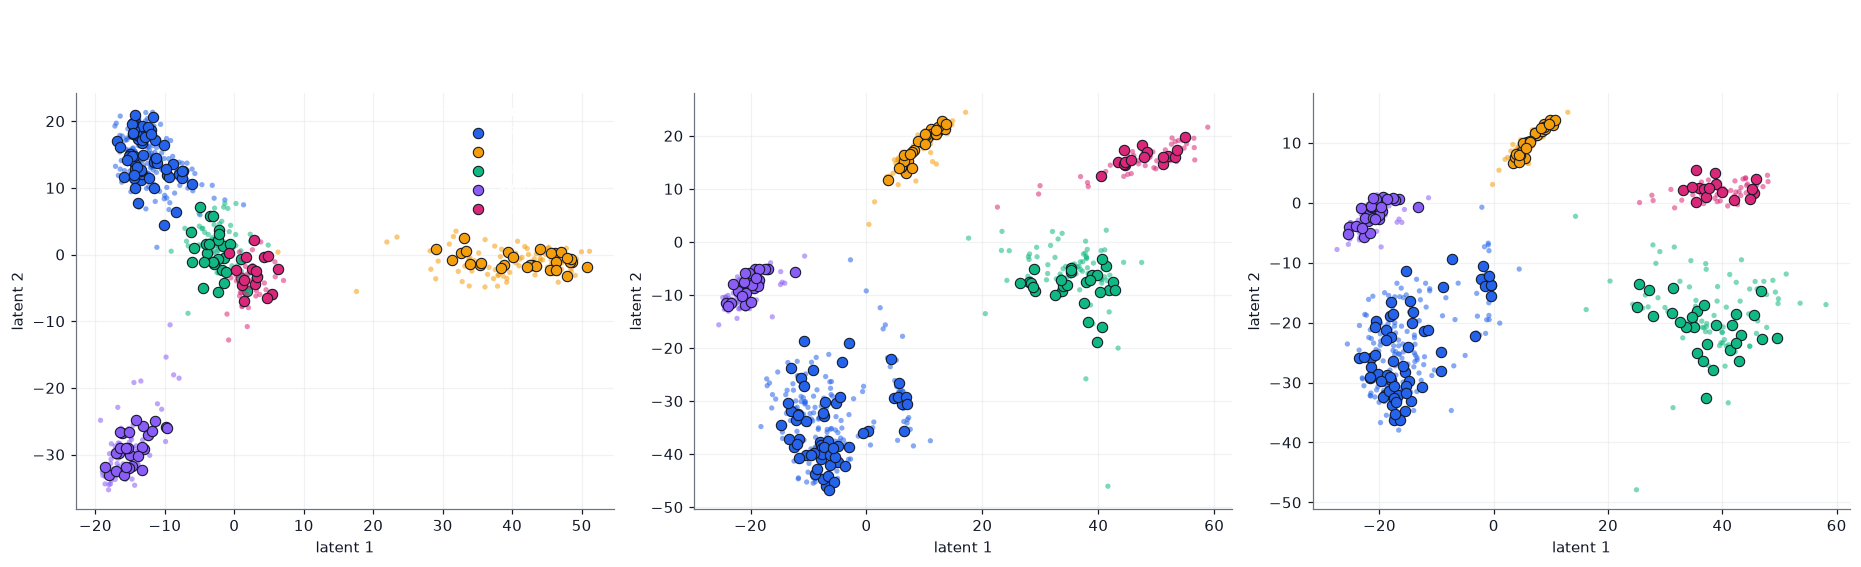

In [17]:
def encode(method, k, seed, X):
    if method == "PCA":
        return X @ Vt_tr[:k].T
    return store[(method, k, seed)][1].predict(X, verbose=0)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))
for ax, method in zip(axes, ["PCA", "Autoencoder", "Denoising autoencoder"]):
    codes_tr, codes_te = encode(method, 2, 0, Z["train"]), encode(method, 2, 0, Z["test"])
    for i, c in enumerate(GENE_CLASSES):
        ax.scatter(codes_tr[y["train"] == i, 0], codes_tr[y["train"] == i, 1], s=12, alpha=0.55, color=CLASS_COLORS[c], edgecolor="none")
        ax.scatter(codes_te[y["test"] == i, 0], codes_te[y["test"] == i, 1], s=46, color=CLASS_COLORS[c], edgecolor=COLORS["dark"], linewidth=0.7, label=c)
    ax.set_title(f"{method} (k = 2)"); ax.set_xlabel("latent 1"); ax.set_ylabel("latent 2")
axes[0].legend(title="cancer type (outlined: test)", fontsize=8, ncol=1)
fig.suptitle("Two-dimensional latent spaces learned without labels (colour = cancer type, shown only for display)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.02)
finish(fig, "05_latent_maps")

Remember that the axes of an autoencoder have no intrinsic meaning (Section 6.2): the map can be rotated, reflected, or stretched without changing what it encodes, and a different seed gives a different-looking map. What can be compared is the **neighbourhood structure**: whether tumours of the same type are close together.

### 13.2 Quantitative evaluation: classification and clustering on the codes

For every method and bottleneck size, we encode the training and the evaluation tumours, standardize the codes, and compute

- the accuracy of a **5-nearest-neighbour** classifier trained on the training codes;
- the accuracy of a **ridge classifier** (penalty equal to the number of code dimensions);
- the **ARI** of **k-means** (5 clusters, fitted on the training codes and applied to the evaluation codes) against the true cancer types.

The sweep over $k$ uses the **validation** set; the final table at $K_{\text{main}}$ uses the **test** set, with all choices ($k$, noise level, classifiers) fixed in advance. The "raw genes" row uses the 2000 standardized genes as the representation.

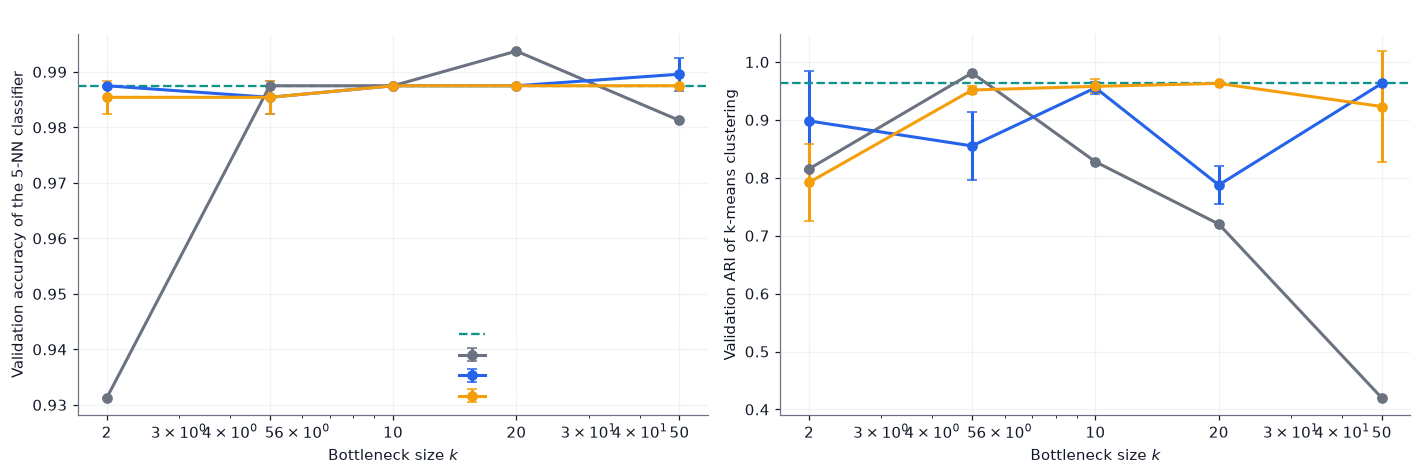

Raw genes (validation): kNN accuracy 0.988 | ridge accuracy 0.988 | ARI 0.963


In [18]:
def evaluate_codes(codes_tr, y_tr, codes_ev, y_ev):
    ctr, cev = standardize_codes(codes_tr, codes_ev)
    acc_knn, f1_knn = macro_f1_and_accuracy(y_ev, knn_predict(ctr, y_tr, cev))
    acc_ridge, _ = macro_f1_and_accuracy(y_ev, ridge_predict(ctr, y_tr, cev, lam=float(ctr.shape[1])))
    centers = kmeans_numpy(ctr, 5)
    return {"kNN accuracy": acc_knn, "kNN macro-F1": f1_knn, "ridge accuracy": acc_ridge, "ARI": adjusted_rand_index(y_ev, assign_clusters(cev, centers))}

sweep = {m: {k: [] for k in K_GRID} for m in ["PCA", "Autoencoder", "Denoising autoencoder"]}
for k in K_GRID:
    sweep["PCA"][k].append(evaluate_codes(encode("PCA", k, 0, Z["train"]), y["train"], encode("PCA", k, 0, Z["val"]), y["val"]))
    for method in ["Autoencoder", "Denoising autoencoder"]:
        for s in range(N_SEEDS):
            sweep[method][k].append(evaluate_codes(encode(method, k, s, Z["train"]), y["train"], encode(method, k, s, Z["val"]), y["val"]))
raw_val = evaluate_codes(Z["train"], y["train"], Z["val"], y["val"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, key, label in zip(axes, ["kNN accuracy", "ARI"], ["Validation accuracy of the 5-NN classifier", "Validation ARI of k-means clustering"]):
    for method in sweep:
        mean = np.array([np.mean([r[key] for r in sweep[method][k]]) for k in K_GRID]); sd = np.array([np.std([r[key] for r in sweep[method][k]]) for k in K_GRID])
        ax.errorbar(K_GRID, mean, yerr=sd, marker="o", capsize=3, color=METHOD_COLORS[method], label=method)
    ax.axhline(raw_val[key], color=METHOD_COLORS["Raw genes"], linestyle="--", linewidth=1.5, label="raw standardized genes (2000)")
    ax.set_xscale("log"); ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID); ax.set_xlabel("Bottleneck size $k$"); ax.set_ylabel(label); ax.set_title(label.split(" of ")[0] + " against $k$")
axes[0].legend(fontsize=8.5, loc="lower right")
finish(fig, "06_downstream_vs_k")
print("Raw genes (validation): kNN accuracy", round(raw_val["kNN accuracy"], 3), "| ridge accuracy", round(raw_val["ridge accuracy"], 3), "| ARI", round(raw_val["ARI"], 3))

In [19]:
# Final comparison at K_MAIN on the TEST set (all choices were fixed before looking at it).
rows = {}
rows["Raw genes (2000)"] = evaluate_codes(Z["train"], y["train"], Z["test"], y["test"])
pca_row = evaluate_codes(encode("PCA", K_MAIN, 0, Z["train"]), y["train"], encode("PCA", K_MAIN, 0, Z["test"]), y["test"])
rows[f"PCA (k = {K_MAIN})"] = pca_row
for method in ["Autoencoder", "Denoising autoencoder"]:
    runs = [evaluate_codes(encode(method, K_MAIN, s, Z["train"]), y["train"], encode(method, K_MAIN, s, Z["test"]), y["test"]) for s in range(N_SEEDS)]
    rows[f"{method} (k = {K_MAIN})"] = {key: (np.mean([r[key] for r in runs]), np.std([r[key] for r in runs])) for key in runs[0]}

def fmt(v):
    return f"{v[0]:.3f} \u00b1 {v[1]:.3f}" if isinstance(v, tuple) else f"{v:.3f}"
display(pd.DataFrame({name: {key: fmt(v) for key, v in r.items()} for name, r in rows.items()}).T)
print(f"Test set: {len(y['test'])} tumours. Chance accuracy (majority class): {np.bincount(y['test']).max() / len(y['test']):.3f}; ARI of random clusters: about 0.")

,kNN accuracy,kNN macro-F1,ridge accuracy,ARI
Raw genes (2000),1.000,1.000,1.000,1.000
PCA (k = 10),1.000,1.000,1.000,0.892
Autoencoder (k = 10),1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
Denoising autoencoder (k = 10),1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000


Test set: 160 tumours. Chance accuracy (majority class): 0.375; ARI of random clusters: about 0.


Compare the rows. With five very different tissues, the classes are close to separable already in the raw genes, so most representations reach a very high accuracy; the interesting differences appear at **small $k$**, in the clustering quality (ARI), and in how much the compressed codes lose relative to the raw genes. The point of the representation is not to *beat* the raw genes with 2000 features, but to **keep the information with 10 numbers** (200× fewer), which makes downstream models (and visualization) simpler and less prone to overfitting.

## 14. Experiment E3 — denoising

Does the denoising autoencoder remove noise better than the plain autoencoder or PCA? We corrupt the **test** profiles with Gaussian noise of increasing standard deviation $\sigma$ (in standardized units, so $\sigma = 1$ means noise as large as the biological variation of a gene), reconstruct, and compare with the **clean** profile. Doing nothing (outputting the noisy input) has error $\sigma^2$; PCA denoises by projecting onto the top-$k$ components.

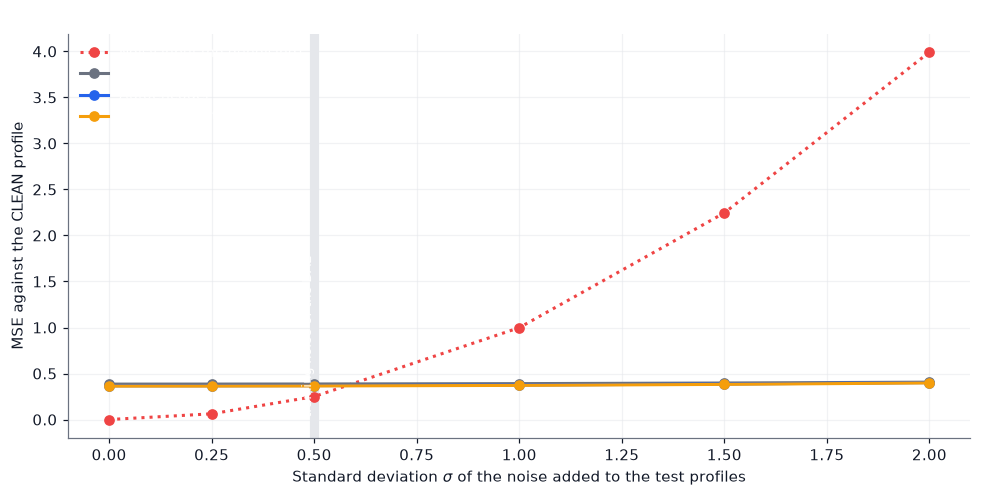

,Noisy input (no denoising),PCA,Autoencoder,Denoising autoencoder
σ = 0.0,0.000,0.385,0.367,0.363
σ = 0.25,0.062,0.385,0.367,0.363
σ = 0.5,0.250,0.386,0.369,0.365
σ = 1.0,0.998,0.390,0.375,0.371
σ = 1.5,2.246,0.397,0.386,0.382
σ = 2.0,3.992,0.406,0.402,0.398


In [20]:
sigmas = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
noise_rng = np.random.default_rng(123)
noise_draws = noise_rng.normal(size=Z["test"].shape).astype("float32")

denoise = {"Noisy input (no denoising)": [], "PCA": [], "Autoencoder": [], "Denoising autoencoder": []}
Vk = Vt_tr[:K_MAIN]
for sg in sigmas:
    noisy = Z["test"] + sg * noise_draws
    denoise["Noisy input (no denoising)"].append(mse(Z["test"], noisy))
    denoise["PCA"].append(mse(Z["test"], (noisy @ Vk.T) @ Vk))
    for method in ["Autoencoder", "Denoising autoencoder"]:
        denoise[method].append(np.mean([mse(Z["test"], store[(method, K_MAIN, s)][0].predict(noisy, verbose=0)) for s in range(N_SEEDS)]))

fig, ax = plt.subplots(figsize=(9, 4.6))
styles = {"Noisy input (no denoising)": (COLORS["red"], ":"), **{m: (METHOD_COLORS[m], "-") for m in ["PCA", "Autoencoder", "Denoising autoencoder"]}}
for name, vals in denoise.items():
    ax.plot(sigmas, vals, marker="o", color=styles[name][0], linestyle=styles[name][1], label=name)
ax.axvline(DAE_NOISE, color=COLORS["light"], linewidth=6, zorder=0); ax.annotate("training noise of the DAE", (DAE_NOISE, 0.02), fontsize=8.5, rotation=90, va="bottom", ha="right")
ax.set_xlabel("Standard deviation $\\sigma$ of the noise added to the test profiles"); ax.set_ylabel("MSE against the CLEAN profile")
ax.set_title(f"Denoising of test tumours with a {K_MAIN}-dimensional bottleneck"); ax.legend()
finish(fig, "07_denoising")
display(pd.DataFrame(denoise, index=[f"\u03c3 = {s}" for s in sigmas]).round(3))

Observe the three regimes: (1) at $\sigma = 0$ the denoising autoencoder is not better than the plain autoencoder (it was not trained for that); (2) at moderate noise the **bottleneck itself** is a strong denoiser — every method is far below the "no denoising" line $\sigma^2$, because noise that is spread across 2000 genes mostly falls *outside* the low-dimensional subspace that the model reconstructs; (3) when the test noise differs from the training noise, an autoencoder trained with a *different* corruption (here the plain one without any) degrades differently from the DAE. Which method is best depends on the noise level, and matching the training corruption to the expected noise matters.

## 15. Experiment E4 — reconstruction error as a novelty detector (and a leakage trap)

An autoencoder trained on some cancer types reconstructs **those** types well. A tumour of a type it has *never seen* may be reconstructed worse, so the reconstruction error can serve as a **novelty score**. We test this by training on four cancer types and scoring test tumours of the **held-out** type against test tumours of the four seen types (AUC: probability that a novel tumour has a larger reconstruction error than a seen one).

**The leakage trap.** The preprocessing (gene selection by variance, standardization) learns from the data. If it is fitted on *all* training tumours, **including those of the held-out type**, information about the novel type enters the pipeline before the autoencoder is trained. The correct procedure fits *everything* — gene selection, scaling, the model — **without** the novel type. We run both for PCA (cheap, all five types) and for the autoencoder (held-out type COAD only, to limit the run time).

In [21]:
def novelty_scores(held_out, leaky=False, use_ae=False, seed=SEED):
    """Reconstruction-error AUC for detecting the held-out class. leaky=True fits gene selection and scaling on ALL training tumours."""
    keep_tr, keep_va = y["train"] != held_out, y["val"] != held_out
    fit_rows = np.arange(len(tr)) if leaky else np.flatnonzero(keep_tr)
    prep_c = fit_preprocessing(X_raw[tr][fit_rows])
    Ztr = apply_preprocessing(X_raw[tr][keep_tr], prep_c); Zva = apply_preprocessing(X_raw[va][keep_va], prep_c); Zte = apply_preprocessing(X_raw[te], prep_c)
    is_novel = (y["test"] == held_out).astype(int)
    out = {}
    _, _, Vt_c = np.linalg.svd(Ztr.astype(np.float64), full_matrices=False)
    Vk_c = Vt_c[:K_MAIN]
    err_pca = np.mean((Zte - (Zte @ Vk_c.T) @ Vk_c) ** 2, axis=1)
    out["PCA"] = auc_rank(is_novel, err_pca)
    if use_ae:
        ae, _, _, _ = train_autoencoder(K_MAIN, seed, Ztr, Zva, name=f"novelty_{GENE_CLASSES[held_out]}{'_leaky' if leaky else ''}")
        err_ae = np.mean((Zte - ae.predict(Zte, verbose=0)) ** 2, axis=1)
        out["Autoencoder"] = auc_rank(is_novel, err_ae)
        out["_errors"] = (err_ae, is_novel)
    return out

classes_to_test = [GENE_CLASSES.index("COAD")] if QUICK_MODE else list(range(len(GENE_CLASSES)))
novelty = {}
t0 = time.time()
for c in classes_to_test:
    proper = novelty_scores(c, leaky=False, use_ae=(GENE_CLASSES[c] == "COAD"))
    leaky = novelty_scores(c, leaky=True, use_ae=(GENE_CLASSES[c] == "COAD"))
    novelty[c] = {"proper": proper, "leaky": leaky}
print(f"Done in {time.time() - t0:.0f} s")

rows = []
for c, res in novelty.items():
    rows.append({"held-out type": GENE_CLASSES[c], "PCA AUC (correct pipeline)": round(res["proper"]["PCA"], 3), "PCA AUC (leaky preprocessing)": round(res["leaky"]["PCA"], 3),
                 "AE AUC (correct)": round(res["proper"].get("Autoencoder", float("nan")), 3), "AE AUC (leaky)": round(res["leaky"].get("Autoencoder", float("nan")), 3)})
display(pd.DataFrame(rows).set_index("held-out type"))

Done in 38 s


,PCA AUC (correct pipeline),PCA AUC (leaky preprocessing),AE AUC (correct),AE AUC (leaky)
held-out type,,,,
BRCA,0.992,0.755,NaN,NaN
KIRC,1.000,0.465,NaN,NaN
LUAD,0.984,0.764,NaN,NaN
PRAD,0.990,0.337,NaN,NaN
COAD,1.000,0.990,1.0,1.0


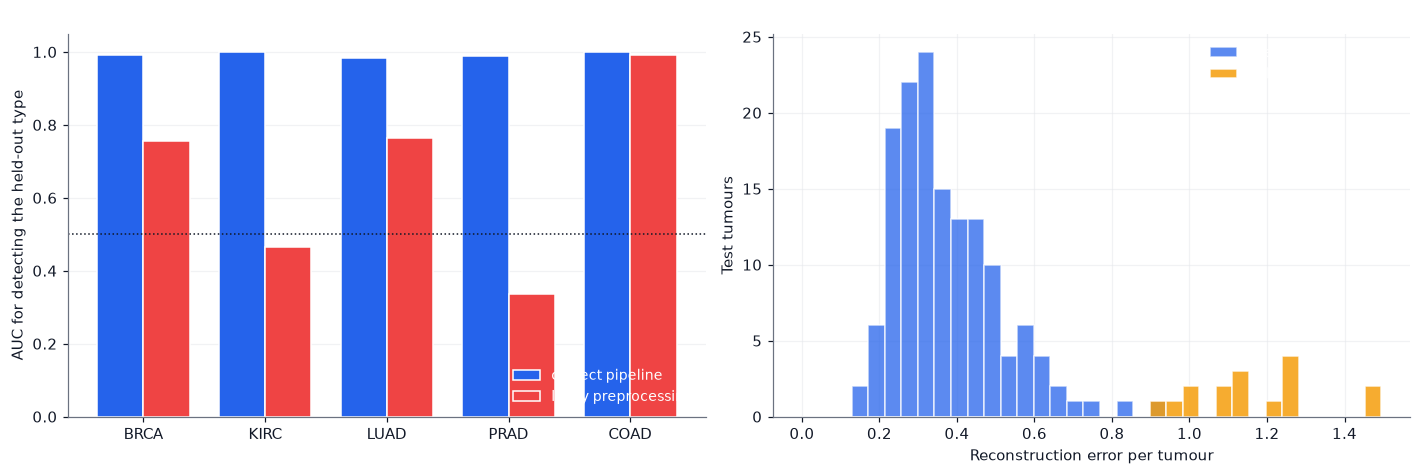

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
names_c = [GENE_CLASSES[c] for c in novelty]; x = np.arange(len(names_c)); width = 0.38
axes[0].bar(x - width / 2, [novelty[c]["proper"]["PCA"] for c in novelty], width, color=COLORS["blue"], label="correct pipeline", edgecolor="white")
axes[0].bar(x + width / 2, [novelty[c]["leaky"]["PCA"] for c in novelty], width, color=COLORS["red"], label="leaky preprocessing", edgecolor="white")
axes[0].axhline(0.5, color=COLORS["dark"], linestyle=":", linewidth=1); axes[0].set_xticks(x); axes[0].set_xticklabels(names_c)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("AUC for detecting the held-out type"); axes[0].set_title(f"Novelty detection by PCA reconstruction error (k = {K_MAIN})"); axes[0].legend(loc="lower right"); axes[0].grid(axis="x", visible=False)

coad = GENE_CLASSES.index("COAD")
if coad in novelty and "_errors" in novelty[coad]["proper"]:
    err, is_novel = novelty[coad]["proper"]["_errors"]
    bins = np.linspace(0, max(err.max(), 1e-6) * 1.02, 36)
    axes[1].hist(err[is_novel == 0], bins=bins, color=COLORS["blue"], alpha=0.75, edgecolor="white", label="seen types")
    axes[1].hist(err[is_novel == 1], bins=bins, color=COLORS["orange"], alpha=0.85, edgecolor="white", label="held-out type (COAD)")
    axes[1].set_xlabel("Reconstruction error per tumour"); axes[1].set_ylabel("Test tumours")
    axes[1].set_title(f"Autoencoder (correct pipeline): AUC = {novelty[coad]['proper']['Autoencoder']:.3f}"); axes[1].legend()
finish(fig, "08_novelty_detection")

How to read this: an AUC near 1 means that reconstruction error identifies the unseen type; 0.5 means no information. Differences between the *correct* and *leaky* bars show how preprocessing fitted on the novel type changes the score — a reminder (Notebook 07) that **every** data-dependent step belongs inside the training procedure. Note also that novelty detection by reconstruction error is **not guaranteed**: a held-out type that lies near the span of the training types is reconstructed well and is missed, and an unusual *seen* sample (a technical outlier) can be flagged. Treat the score as a hint to inspect samples, not as a classifier.

## 16. What does a reconstruction look like?

A direct look at reconstructions of test tumours: original profile, autoencoder reconstruction, and residual, for the 60 highest-variance genes of the training set (all values standardized).

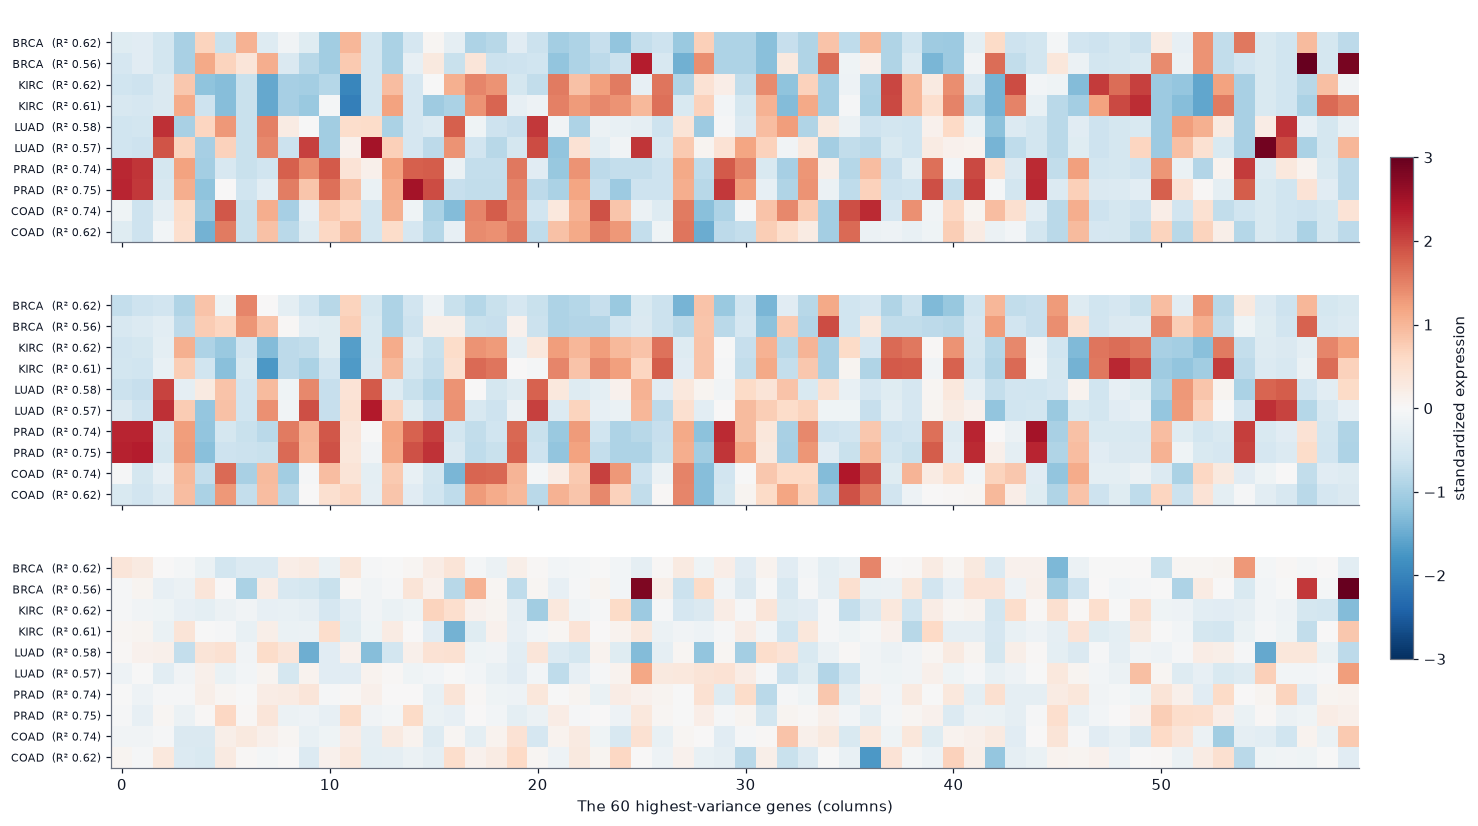

In [23]:
ae_main = store[("Autoencoder", K_MAIN, 0)][0]
rep_idx = np.concatenate([np.flatnonzero(y["test"] == c)[:2] for c in range(len(GENE_CLASSES))])                # two test tumours per cancer type
orig = Z["test"][rep_idx][:, :60]
recon = ae_main.predict(Z["test"][rep_idx], verbose=0)[:, :60]
per_sample_r2 = 1 - np.mean((Z["test"][rep_idx] - ae_main.predict(Z["test"][rep_idx], verbose=0)) ** 2, axis=1)

fig, axes = plt.subplots(3, 1, figsize=(14, 7.6), sharex=True)
for ax, (M_, title) in zip(axes, [(orig, "Original (standardized expression)"), (recon, f"Autoencoder reconstruction (k = {K_MAIN})"), (orig - recon, "Residual (original \u2212 reconstruction)")]):
    im = ax.imshow(M_, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest"); ax.grid(False)
    ax.set_yticks(range(len(rep_idx))); ax.set_yticklabels([f"{GENE_CLASSES[y['test'][i]]}  (R\u00b2 {r:.2f})" for i, r in zip(rep_idx, per_sample_r2)], fontsize=7.5)
    ax.set_title(title, fontsize=10.5)
axes[-1].set_xlabel("The 60 highest-variance genes (columns)")
fig.subplots_adjust(left=0.09, right=0.9, hspace=0.25, top=0.95, bottom=0.07)
cax = fig.add_axes([0.92, 0.2, 0.015, 0.6])
fig.colorbar(im, cax=cax, label="standardized expression")
finish(fig, "09_reconstructions", tight=False)

The reconstruction captures the coarse pattern of each tumour (the programmes that are shared by tumours of the same type) while the residual contains gene-specific variation that the 10 numbers cannot represent — which can be biological detail or technical noise; the autoencoder cannot tell the two apart.

## 17. Interpretation and limitations

**What the results can support.** Compressing tumour expression profiles into about ten numbers retains most of the variance and most of the class structure, without ever using the labels; a denoising autoencoder is a more robust encoder at high noise; and reconstruction error can flag samples unlike the training data.

**What they do not support.**

1. **Latent dimensions are not biological factors.** The codes are only defined up to transformations (Section 6.2). A latent axis does not "mean" a pathway, and two seeds give different-looking spaces. Interpretation requires additional work (for example, relating latent dimensions to gene sets), and *unsupervised models can encode technical variation* (batch, library size, tissue-processing differences) as readily as biology.
2. **A nonlinear autoencoder was not much better than PCA** for this data set at this sample size (check your numbers). With a few hundred samples, the extra flexibility of a deep network is largely absorbed by regularization; a linear method is often a strong and much cheaper baseline. Claims that a deep model "discovers" structure must be compared with PCA.
3. **Easy problem.** Five very different tissues are separable almost anywhere. Subtle structure (subtypes within a cancer, response to therapy) is harder, and the benefit of the compression has to be evaluated for that question.
4. **Novelty detection is heuristic** (Section 15), and its AUC depends on which type is held out and on how the pipeline was fitted.
5. **Evaluation uses labels** that were never used in training — the right way to judge a representation — but the numbers still come from one split of 801 tumours and a few seeds, so small differences are not significant.
6. **Gene names are anonymized**, so we cannot inspect which genes drive each latent dimension.

## 18. Saving the encoder with its preprocessing

To reuse the encoder on new tumours one needs the **complete** pipeline: the selected gene indices, the training means and standard deviations, and the encoder. We save them together.

In [24]:
enc_main = store[("Autoencoder", K_MAIN, 0)][1]
dae_main = store[("Denoising autoencoder", K_MAIN, 0)][1]
enc_main.save(os.path.join(ARTIFACT_DIR, f"encoder_ae_k{K_MAIN}.keras")); store[("Autoencoder", K_MAIN, 0)][2].save(os.path.join(ARTIFACT_DIR, f"decoder_ae_k{K_MAIN}.keras"))
dae_main.save(os.path.join(ARTIFACT_DIR, f"encoder_dae_k{K_MAIN}.keras"))
np.savez(os.path.join(ARTIFACT_DIR, "preprocessing.npz"), cols=prep["cols"], mu=prep["mu"], sd=prep["sd"], pca_components=Vt_tr[:K_MAIN])

meta = {"dataset": "UCI Gene expression cancer RNA-Seq (Fiorini, 2016), DOI 10.24432/C5R88H, CC BY 4.0",
        "preprocessing": f"top {GENE_TOP_K} genes by training variance, then z-scoring with training mean/std (arrays in preprocessing.npz)",
        "split": {"kind": "stratified 60/20/20", "seed": SEED, "train": int(len(tr)), "validation": int(len(va)), "test": int(len(te))},
        "k_main": K_MAIN, "denoising_noise_std": DAE_NOISE, "seeds": N_SEEDS,
        "validation_mse": {m: {str(k): float(np.mean(v[k])) for k in K_GRID} for m, v in val_mse.items()},
        "versions": {"python": sys.version.split()[0], "keras": keras.__version__, "backend": keras.backend.backend(), "numpy": np.__version__}}
with open(os.path.join(ARTIFACT_DIR, "autoencoder_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

def encode_new_samples(X_raw_rows, encoder=enc_main, prep_=prep):
    """Raw expression rows (all 20,531 genes, same order as data.csv) -> latent codes."""
    return encoder.predict(apply_preprocessing(np.asarray(X_raw_rows, dtype="float32"), prep_), verbose=0)

print("Latent codes of two new tumours:\n", np.round(encode_new_samples(X_raw[te[:2]]), 3))
print("Identical to the codes computed during the experiments:", np.allclose(encode_new_samples(X_raw[te[:2]]), enc_main.predict(Z["test"][:2], verbose=0), atol=1e-5))

Latent codes of two new tumours:
 [[-13.52    7.838 -15.212  13.158  10.623   6.628  -3.926 -12.892  -1.215
    4.021]
 [ -2.068 -14.788   7.182  -8.032   9.376   0.726   6.034  -5.852  -3.899
    8.968]]
Identical to the codes computed during the experiments: True


## 19. What did we learn?

1. An **autoencoder** learns an encoder $f_\phi$ and a decoder $g_\theta$ by minimizing the reconstruction error; without a constraint (bottleneck, noise, penalty) it would learn the identity. Labels are not needed; they are used only to *evaluate* the representation.
2. **Eckart–Young:** the best rank-$k$ approximation is the truncated SVD, with error $\sum_{i>k}\sigma_i^2$. **A linear autoencoder is PCA**: gradient descent reaches the PCA loss and the PCA subspace (principal angles near 0), but the latent coordinates are defined only up to an invertible linear map.
3. The MSE is a **Gaussian likelihood**; standardization gives each gene the same weight and makes $\text{MSE} = 1 - R^2$.
4. A **denoising autoencoder** learns $\mathbb{E}[x\mid\tilde{x}] = \tilde{x} + \sigma^2\nabla\log p_\sigma(\tilde{x})$ (**Tweedie's formula**, verified numerically); the denoiser implicitly learns the data density.
5. The **ELBO** satisfies $\log p(x) = \text{ELBO} + D_{\mathrm{KL}}(q\Vert p(z\mid x))$, with a closed-form Gaussian KL and the **reparameterization trick** (all verified numerically).
6. On 480 training tumours a nonlinear autoencoder is **not guaranteed to beat PCA**; the comparison with PCA as a baseline is essential.
7. Latent spaces are judged with label-based **downstream tasks** (nearest-neighbour and linear classification) and **clustering** (k-means, ARI) — computed *after* training, never used for it.
8. Bottlenecks denoise; **reconstruction error** can flag novel samples, but all preprocessing must be fitted **without** the novel samples (leakage).
9. Latent dimensions have **no intrinsic biological meaning**; unsupervised models also encode technical variation.

### Key terms

| Term | Meaning |
|---|---|
| Encoder, decoder, code (latent vector) | $f_\phi$, $g_\theta$, and $z = f_\phi(x)$ |
| Bottleneck | A code dimension $k \ll d$ that forces compression |
| Reconstruction loss | $\lVert x - g(f(x))\rVert^2$ (Gaussian negative log-likelihood) |
| $R^2$ | Fraction of variance explained, $1 - \text{MSE}$ for standardized data |
| Eckart–Young theorem | Truncated SVD is the best low-rank approximation |
| Principal angles | Angles between two subspaces (0 = identical) |
| Denoising autoencoder | Trained to reconstruct the clean input from a corrupted one |
| Score, Tweedie's formula | $\nabla\log p$; $\mathbb{E}[x\mid\tilde{x}] = \tilde{x} + \sigma^2\,\text{score}$ |
| ELBO | Evidence lower bound, reconstruction term minus KL to the prior |
| Reparameterization trick | $z = \mu + \sigma\odot\varepsilon$ to differentiate through sampling |
| ARI | Adjusted Rand index: chance-corrected agreement of two partitions |
| Novelty detection | Flagging samples that the model reconstructs poorly |

## 20. Exercises

### A. Mathematics

1. Show that for centred data the first principal direction $v_1$ maximizes $\operatorname{Var}(Xv)$ subject to $\lVert v\rVert = 1$, and that it is the top eigenvector of $\frac{1}{n}X^{\top}X$.
2. A centred data matrix has singular values $(10, 6, 3, 1, 0.5)$ and $n = 100$. Compute the fraction of variance explained by $k = 1, 2, 3$ and the minimum per-sample reconstruction error $\frac{1}{n}\sum_{i>k}\sigma_i^2$.
3. For the linear autoencoder, derive $\partial L/\partial W_d$ and $\partial L/\partial W_e$ (Section 6.2). Show that at a stationary point with $W_d^{\top}$ of full rank, the product $W_eW_d$ is the orthogonal projector onto the span of $k$ right singular vectors of $X$.
4. Prove the **non-uniqueness**: if $(W_e, W_d)$ is a minimizer, so is $(W_eA, A^{-1}W_d)$ for any invertible $A$. How many degrees of freedom does this add, and how could one remove them (for example, by requiring orthonormal columns and decorrelated codes)?
5. Derive Tweedie's formula for Gaussian noise: show $\mathbb{E}[x\mid\tilde{x}] = \tilde{x} + \sigma^2\nabla\log p_\sigma(\tilde{x})$ starting from $p_\sigma(\tilde{x}) = \int p(x)\,\mathcal{N}(\tilde{x}; x, \sigma^2)\,dx$ and differentiating under the integral.
6. Derive the closed-form KL divergence between $\mathcal{N}(\mu, \sigma^2)$ and $\mathcal{N}(0, 1)$ in one dimension, and show that it is minimized at $\mu = 0$, $\sigma = 1$.
7. Prove the ELBO identity $\log p(x) = \text{ELBO} + D_{\mathrm{KL}}(q\Vert p(z\mid x))$.
8. Show that the adjusted Rand index of two *independent* random partitions has expected value 0 (hint: the pair-counting expectation under the hypergeometric model).

### B. Programming

1. Add a **sparse** autoencoder (an L1 activity regularizer on the code, `activity_regularizer=keras.regularizers.L1(1e-3)` on the latent layer) and compare the codes with the plain AE (how many code units are active per sample?).
2. Replace the Gaussian noise of the DAE by **masking noise** (randomly set 20% of the genes to zero, using a `Dropout(0.2)` layer in front of the encoder). Compare with Section 14.
3. Vary the DAE noise level (0.25, 0.5, 1.0) and the L2 weight ($10^{-5}$, $10^{-4}$, $10^{-3}$) and plot the validation error and the downstream accuracy. Use several seeds.
4. Train an autoencoder with **two hidden layers** (512 and 128 units) and compare with the one-hidden-layer model: is a deeper network better for this sample size?
5. Perform **latent interpolation**: take the codes of one tumour of type BRCA and one of type KIRC, decode points on the straight line between them, and classify the decoded profiles with a ridge classifier trained on the real tumours. Does the predicted class change smoothly along the path?
6. Compute the **trustworthiness** (or the overlap of $k$-nearest-neighbour sets) between the original 2000-dimensional space and the latent space, for PCA and the AE.
7. Evaluate the stability of the latent space across seeds: for two seeds, fit the best linear map between their codes and report the relative residual (as in Section 6). How similar are the representations?
8. Implement a **VAE** in Keras 3: encoder to `z_mean` and `z_log_var`, a `Sampling` layer (`z = z_mean + exp(0.5 * z_log_var) * epsilon`, with `keras.random.normal` and a `keras.random.SeedGenerator`) that adds the KL term with `self.add_loss(beta * kl / D)` (so that the total is the per-gene MSE plus a scaled KL), and a decoder. Compare its latent map with Section 13.1, and decode samples from $\mathcal{N}(0, I)$.
9. Repeat the novelty-detection experiment for all five held-out types with the autoencoder (not only COAD) and with three seeds, and report mean ± SD of the AUC.

### C. Research thinking

1. A latent dimension of your autoencoder separates two clusters of tumours. List the confounders you would need to rule out before calling it a "biological factor" (batch, sequencing depth, tissue purity, patient age, centre of collection).
2. You want to use the latent space to **integrate** data from two hospitals. What could go wrong if the autoencoder learns the hospital as the main axis of variation, and how would you check?
3. Under which conditions would you expect a nonlinear autoencoder to clearly outperform PCA (think about the structure of the data and the number of samples)? Design a simulation that demonstrates it.
4. Why is it problematic to use the **labels** to choose the bottleneck size $k$ and then to report the downstream accuracy on the same labels? How would you avoid it?

## 21. Further exploration and references

### Dataset

- Fiorini, S. (2016). *Gene expression cancer RNA-Seq* [Dataset]. UCI Machine Learning Repository. <https://doi.org/10.24432/C5R88H> (CC BY 4.0).
- Weinstein, J. N., *et al.* (2013). The Cancer Genome Atlas Pan-Cancer analysis project. *Nature Genetics*, 45(10), 1113–1120.

### Autoencoders and representation learning

- Eckart, C. and Young, G. (1936). The approximation of one matrix by another of lower rank. *Psychometrika*, 1, 211–218.
- Baldi, P. and Hornik, K. (1989). Neural networks and principal component analysis: learning from examples without local minima. *Neural Networks*, 2, 53–58.
- Hinton, G. E. and Salakhutdinov, R. R. (2006). Reducing the dimensionality of data with neural networks. *Science*, 313, 504–507.
- Vincent, P., Larochelle, H., Bengio, Y., and Manzagol, P.-A. (2008). Extracting and composing robust features with denoising autoencoders. *ICML*.
- Vincent, P. (2011). A connection between score matching and denoising autoencoders. *Neural Computation*, 23, 1661–1674.
- Alain, G. and Bengio, Y. (2014). What regularized auto-encoders learn from the data-generating distribution. *Journal of Machine Learning Research*, 15, 3563–3593.
- Efron, B. (2011). Tweedie's formula and selection bias. *Journal of the American Statistical Association*, 106, 1602–1614.
- Kingma, D. P. and Welling, M. (2014). Auto-encoding variational Bayes. *ICLR*.
- Higgins, I., *et al.* (2017). $\beta$-VAE: learning basic visual concepts with a constrained variational framework. *ICLR*.

### Biological applications

- Way, G. P. and Greene, C. S. (2018). Extracting a biologically relevant latent space from cancer transcriptomes with variational autoencoders. *Pacific Symposium on Biocomputing*, 23, 80–91.
- Eraslan, G., Simon, L. M., Mircea, M., Mueller, N. S., and Theis, F. J. (2019). Single-cell RNA-seq denoising using a deep count autoencoder. *Nature Communications*, 10, 390.
- Lopez, R., Regier, J., Cole, M. B., Jordan, M. I., and Yosef, N. (2018). Deep generative modeling for single-cell transcriptomics. *Nature Methods*, 15, 1053–1058.

### Keras documentation

- [`GaussianNoise`](https://keras.io/api/layers/regularization_layers/gaussian_noise/), [`Dropout`](https://keras.io/api/layers/regularization_layers/dropout/), [regularizers](https://keras.io/api/layers/regularizers/)
- Keras example guides: *Convolutional autoencoder for image denoising* and *Variational AutoEncoder*.

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 14 (autoencoders) and chapter 13 (linear factor models, including PCA).
- Hastie, Tibshirani, and Friedman — *The Elements of Statistical Learning*: section 14.5 (principal components) and 14.3 (clustering).
- Chollet — *Deep Learning with Python*: the sections on autoencoders and variational autoencoders.

---

## Next notebook

**12 — End-to-End Deep Learning Project in Bioinformatics**

The final notebook is an **independent project** from the research question to the scientific conclusion: choosing and describing a dataset, cleaning and exploring it, designing and training models, hyperparameter tuning with a leak-free protocol, comparing models fairly, interpreting the results, stating the limitations, and saving and documenting the final model — using everything from Notebooks 01–11.